# Avance 3. Modelos de referencia (*baseline*)

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda**

Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24**

Colaboración científica con el Instituto de Astronomía de la UNAM

---

| Integrante | Matrícula |
|---|---|
| José Florencio Maguey Peralta | A01796727 |
| Erick Alberto Bustos Cruz | A01378966 |
| Luz Copelia Minutti Pérez | A01796921 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

---

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021).

**Objetivos del avance:**

- **3.1** Establecer las medidas de calidad del modelo de aprendizaje automático.
- **3.2** Proporcionar un marco de referencia para evaluar y mejorar modelos más avanzados.

## 1. Planteamiento

El proyecto estima tres propiedades de cada galaxia a partir de su imagen del DESI Legacy Imaging Survey en las bandas g, r y z (Dey et al. 2019):

| Propiedad | Qué mide | Unidad |
|---|---|---|
| **Masa estelar**, log M\* | Cuánta masa hay en estrellas | log₁₀ de masas solares |
| **Tasa de formación estelar**, log SFR | Cuántas estrellas nuevas forma la galaxia por año | log₁₀ de masas solares por año |
| **D4000** | Intensidad del salto espectral en 4000 Å; crece con la edad de las estrellas | adimensional (≈ 1 en galaxias con estrellas jóvenes, ≈ 2 en galaxias con estrellas viejas) |

Las etiquetas provienen de Pipe3D (Sánchez et al. 2022), que mide estas propiedades con la espectroscopía de campo integral de MaNGA. Esa medición es costosa y existe para unas diez mil galaxias, mientras que las imágenes existen para cientos de millones. Un modelo que recupere las propiedades desde la imagen permitiría extender estimaciones de calidad espectroscópica a todo el cielo observado.

Antes de invertir en modelos complejos, este avance responde dos preguntas:

> **¿Es viable estimar estas propiedades con métodos simples, y cuál es el desempeño mínimo que un modelo más avanzado tendrá que superar?**

### 1.1 Los modelos de referencia

Comparamos modelos de complejidad creciente. Cada uno responde una pregunta distinta:

| Nivel | Modelo | Entrada | Pregunta que responde |
|---|---|---|---|
| **Piso** | Predecir siempre el valor promedio de las galaxias de entrenamiento | Ninguna | ¿Qué error comete un modelo que no usa ninguna información? Equivale a adivinar |
| **B1. Relación color–masa** | En masa, una regresión lineal con la forma de Taylor et al. (2011); en SFR y D4000, una regresión lineal o un bosque aleatorio con las mismas dos variables, según cuál funcione mejor en validación cruzada | El color g − i y la magnitud absoluta Mᵢ, medidos sobre toda la galaxia | ¿Cuánto se logra con el método clásico de la astronomía, sin usar la imagen? |
| **B2. Red convolucional** | Cadena de tres ResNet50 de Katachi (Alfonzo et al. 2024), entrenada con nuestras imágenes DESI | La imagen de 300 × 300 píxeles | ¿Cuánto se logra con un método publicado que usa la imagen completa? Es **el baseline del proyecto** |
| Referencia histórica | Predicciones publicadas de Katachi, galaxia por galaxia | Imágenes de SDSS | ¿Cómo se compara nuestro baseline con el estado actual del problema? |

B1 y B2 se complementan. B1 indica cuánto se puede estimar con solo dos números por galaxia, y B2, cuánto se logra con un modelo que solo ve la imagen. Los modelos que se desarrollen después deberán superar a B2.

### 1.2 Criterios generales

- **Muestra única.** Todas las comparaciones usan las mismas galaxias y la misma partición: entrenamiento, validación y prueba (QCFLAG = 0, partición `split_proyecto`). Cuando un modelo no cubre todas las galaxias, la comparación se hace sobre las que comparten.
- **Decisiones con validación.** La elección de variantes, los criterios de éxito y los umbrales se fijan con entrenamiento y validación, y se registran antes de abrir el conjunto de prueba.
- **Prueba una sola vez.** El conjunto de prueba se abre en la sección 10, después del registro.
- **Incertidumbre.** Cada métrica se reporta con su intervalo de confianza del 95 % por *bootstrap* de galaxias, y la red se entrena con tres semillas.

## 2. Parámetros

| Parámetro | Valor | Significado |
|---|---|---|
| `SEMILLAS` | 42, 7, 2026 | Semillas de la red y de las particiones de validación cruzada. La primera es la principal, fijada antes de ver resultados |
| `EPOCAS` | 30 | Épocas de entrenamiento de la red |
| `N_BOOT` | 2000 | Remuestreos *bootstrap* para los intervalos de confianza |
| `CORTE_SSFR` | −10.8 | Frontera entre galaxias formadoras y apagadas, en log sSFR = log SFR − log M\* [año⁻¹] |
| `MAG_MIN`, `MAG_MAX` | −25, −14 | Intervalo válido de las magnitudes absolutas g, r, i |
| `INCL_MAX` | 70° | Inclinación máxima, con cos i = b/a |
| `TAYLOR` | 1.15, 0.70 | Coeficientes publicados de la relación color–masa (Taylor et al. 2011) |
| `UMBRAL_CATASTROFICO` | 0.3 dex | Un error mayor equivale a errar por más de un factor 2 |
| `MARGEN` | 0.02, 0.02, 0.01 | Diferencia de RMSE que se considera despreciable en log M\*, log SFR y D4000 |
| `N_SHAP` | 48 | Galaxias de validación para los mapas SHAP |

In [1]:
import os
env = os.environ.get            # las variables AV3_* solo se usan en la prueba local reducida

SEMILLAS = tuple(int(s) for s in env("AV3_SEMILLAS", "42,7,2026").split(","))
SEMILLA = SEMILLAS[0]
EPOCAS = int(env("AV3_EPOCAS", "30"))
N_BOOT = int(env("AV3_N_BOOT", "2000"))
LIMITE = int(env("AV3_LIMIT", "0"))             # 0 = todas las galaxias
N_SHAP = int(env("AV3_N_SHAP", "48"))
SHAP_MUESTRAS = int(env("AV3_SHAP_NSAMPLES", "200"))

CORTE_SSFR = -10.8
MAG_MIN, MAG_MAX = -25.0, -14.0
INCL_MAX = 70.0
H_NSA = 0.7                                     # las masas de NSA están en unidades de h⁻² M☉
TAYLOR = (1.15, 0.70)
UMBRAL_CATASTROFICO = 0.3
OBJETIVOS = ["log_mstar", "log_sfr", "d4000"]
NOMBRES = {"log_mstar": "log M* [dex]", "log_sfr": "log SFR [dex]", "d4000": "D4000"}
CORTO = {"log_mstar": "M*", "log_sfr": "SFR", "d4000": "D4000"}
MARGEN = {"log_mstar": 0.02, "log_sfr": 0.02, "d4000": 0.01}
KATACHI_PUBLICADO = {"log_mstar": 0.222, "log_sfr": 0.668, "d4000": 0.100}   # RMSE en sus galaxias de prueba
MASA_DESEABLE = 0.15                            # precisión típica de las masas estelares (dex)

## 3. Entorno

Descargamos el código del repositorio del equipo, de modo que cada resultado quede ligado a una versión concreta, y montamos Google Drive, donde están el catálogo, las imágenes y los resultados. La red necesita GPU.

In [2]:
import sys, json, time, hashlib, subprocess, platform, warnings
from pathlib import Path
from dataclasses import replace
from datetime import datetime, timezone

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/erteck/InferenciaPropiedadesFisicas.git"
REPO_DIR = Path(env("AV3_REPO_DIR", "/content/InferenciaPropiedadesFisicas"))
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hickle", "shap"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], check=True)
sys.path.insert(0, str(REPO_DIR))
COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import ndimage
from IPython.display import display, Markdown
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

from src.katachi_fits import config as K, catalog as C, diagnostico as DG, shap_maps as SM
from src.katachi_fits import aumentacion as AU
from src.katachi_fits.cache import build_cache, cache_dir, load_cache
from src.katachi_fits.chain import ChainTarget
from src.katachi_fits.config import FitsConfig, MejorasConfig, Paths, TrainConfig
from src.katachi_fits.experimentos import Experimento, correr, preparar_datos
from src.katachi_fits.io_guard import WriteGuard, sha256
from src.katachi_fits.train import GPUData, Trainer
from src.katachi_fits.transforms import Normalizer, band_permutation
from src.katachi_fits.variants import DESI

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.precision", 3, "display.max_columns", 40, "display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COLOR = {"Piso": "0.6", "B1": "#2a9d8f", "B2": "#264653", "Katachi": "#e76f51"}
print("Python", platform.python_version(), "· commit", COMMIT[:12], "·", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Mounted at /content/drive
Python 3.13.15 · commit 9cbee175f4ac · cuda NVIDIA A100-SXM4-40GB


## 4. Datos

### 4.1 Muestra y partición

La muestra son las galaxias de MaNGA con etiquetas de Pipe3D que pasaron todos sus controles de calidad (QCFLAG = 0) y cumplen los cortes de Katachi: 8 < log M\* < 12, −4 < log SFR < 2 y D4000 definido. El conjunto de prueba coincide con el de Katachi, lo que permite comparar con sus predicciones publicadas galaxia por galaxia.

In [3]:
BASE = Path(env("AV3_BASE", str(K.DRIVE_BASE)))
DESCARGA = BASE / K.DOWNLOAD_DIRNAME
PLAN_CSV = next(DESCARGA.glob("**/plan.csv"))
CATALOGO = next(p for n in K.TEAM_CATALOG_NAMES for p in DESCARGA.glob(f"**/{n}"))
paths = Paths(base=BASE, plan_csv=PLAN_CSV, inventario_csv=PLAN_CSV.parent / "inventario.csv",
              fits_dir=DESCARGA / "fits", results=BASE / K.RESULTS_DIRNAME, team_catalog=CATALOGO)
guard = WriteGuard(paths.results, paths.read_only)
print("Catálogo:", CATALOGO.name, "· ¿versión acordada?", sha256(CATALOGO) == K.TEAM_CATALOG_SHA256)

plan = C.load_plan(PLAN_CSV, paths.fits_dir)
equipo = C.load_team_catalog(CATALOGO)
scalars = C.load_scalars(paths.external / "scalars.cat")
cohorte, _ = C.build_cohort_team(plan, equipo, scalars)
if LIMITE:
    cohorte = (cohorte.groupby("particion", group_keys=False)
                      .apply(lambda d: d.head(max(LIMITE // 3, 12) if d.name != "Train" else LIMITE)).reset_index(drop=True))
cohorte, _ = C.apply_qc(cohorte, K.QC_GROUPS_INCLUDED)
cohorte = cohorte.reset_index(drop=True)
TAG = f"_lim{LIMITE}" if LIMITE else ""
RES = guard.mkdir(paths.results / f"avance3{TAG}")

cohorte["log_ssfr"] = cohorte.log_sfr - cohorte.log_mstar
cohorte["poblacion"] = np.where(cohorte.log_ssfr < CORTE_SSFR, "apagada", "formadora")
IDX = {p: np.where(cohorte.particion == p)[0] for p in ("Train", "Validation", "Test")}
Y = cohorte[OBJETIVOS].to_numpy(float)
display(pd.crosstab(cohorte.particion, cohorte.poblacion, margins=True, margins_name="total")
          .loc[["Train", "Validation", "Test", "total"]])

Catálogo: catalogo_candidato_9661_galaxias.csv · ¿versión acordada? True


poblacion,apagada,formadora,total
particion,,,
Train,3746,3377,7123
Validation,676,586,1262
Test,465,453,918
total,4887,4416,9303


### 4.2 Las imágenes

Cada galaxia es un recorte central de 300 × 300 píxeles (78.6″) de las imágenes combinadas (*coadds*) de DESI DR10 en las bandas g, r y z. El brillo de cada píxel se comprime con la función asinh(x / 3σ), donde σ es el ruido del cielo, y después se divide entre una constante por banda calculada con las galaxias de entrenamiento. Usamos las mismas constantes para todas las galaxias, de modo que la red conserva el brillo real de cada una, que es necesario para estimar la masa.

También medimos el **radio que encierra la mitad de la luz** (R50) en la banda r. Las secciones de importancia expresan las regiones de la imagen en unidades de R50, porque las galaxias tienen tamaños muy distintos.

Imágenes: (9303, 3, 300, 300) · σ del cielo: [0.00209 0.00396 0.01075] · escala: [5.709 6.027 5.506]
R50 en la banda r: mediana 22.1 px (5.8″)


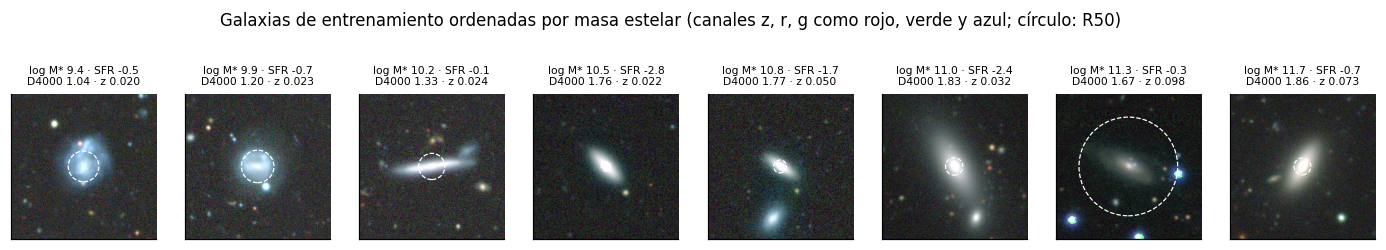

In [4]:
fcfg = FitsConfig()
CACHE = cache_dir(paths.cache, DESI, fcfg, TAG)
build_cache(cohorte, "ruta_local", CACHE, guard, fcfg, variant=DESI, chunk=500, workers=24)
X300, ids, _, _ = load_cache(CACHE, dtype=fcfg.storage_dtype)
assert list(ids) == list(cohorte.mangaid), "El orden de la caché no coincide con la muestra"
NORM = Normalizer.from_json((paths.results / "normalizacion" / f"normalizador_recorte300_beta3{TAG}.json").read_text())
PERM = band_permutation(K.INPUT_BAND_ORDER)
BANDAS_RED = list(K.INPUT_BAND_ORDER)                     # orden de los canales que recibe la red
R50 = DG.radio_mitad_luz(X300, banda=list(K.BANDS).index("r"))
cohorte["R50_px"] = R50
print("Imágenes:", X300.shape, "· σ del cielo:", np.round(NORM.sigma, 5), "· escala:", np.round(NORM.scale, 3))
print(f"R50 en la banda r: mediana {np.median(R50):.1f} px ({np.median(R50) * K.DESI_PIXSCALE_ARCSEC:.1f}″)")

def vista(i):
    x = AU.estirar(torch.from_numpy(X300[i:i + 1].astype(np.float32)), torch.as_tensor(NORM.sigma, dtype=torch.float32),
                   NORM.beta, torch.as_tensor(NORM.scale, dtype=torch.float32))[:, PERM]
    return DG.vista_rgb(x[0].numpy())

tr = cohorte.iloc[IDX["Train"]]
ej = [tr.index[np.argmin(np.abs(tr.log_mstar.to_numpy() - q))] for q in np.quantile(tr.log_mstar, np.linspace(0.03, 0.97, 8))]
fig, ax = plt.subplots(1, 8, figsize=(16, 2.6))
for a, i in zip(ax, ej):
    f = cohorte.loc[i]
    a.imshow(vista(i), origin="lower")
    a.add_patch(plt.Circle((149.5, 149.5), f.R50_px, fill=False, color="w", lw=0.8, ls="--"))
    a.set_title(f"log M* {f.log_mstar:.1f} · SFR {f.log_sfr:.1f}\nD4000 {f.d4000:.2f} · z {f.redshift:.3f}", fontsize=7)
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("Galaxias de entrenamiento ordenadas por masa estelar (canales z, r, g como rojo, verde y azul; círculo: R50)", y=1.04)
plt.show()

La mitad de la luz de una galaxia típica queda dentro de un radio de 22 píxeles (5.8″), así que el recorte de 78.6″ contiene a las galaxias completas con amplio margen. El mosaico muestra la variedad de la muestra: espirales azules de baja masa, discos vistos de canto y, en el extremo de mayor masa, galaxias elípticas rojas y concentradas. En algunas imágenes, una estrella brillante o una galaxia vecina dentro del recorte hace que el R50 medido sea mayor que el real, como en la séptima galaxia. Esto solo afecta a las secciones que usan el R50 como unidad de distancia (8.2 y 8.4), y únicamente en unas pocas galaxias.

### 4.3 Fotometría de toda la galaxia

B1 no usa la imagen, sino mediciones de la galaxia completa tomadas del NASA–Sloan Atlas (NSA; Blanton et al. 2011), un catálogo basado en SDSS: las magnitudes absolutas corregidas en g, r e i, la razón entre los ejes de la galaxia (b/a) y la masa estelar que el propio NSA calcula con esas magnitudes.

Las relaciones entre color y masa se calibran con galaxias cuya fotometría es confiable, por lo que solo las aplicamos a las galaxias que cumplen tres requisitos:

- estar en el NSA y tener medidas las tres magnitudes (g, r, i);
- tener magnitudes absolutas entre −25 y −14, el intervalo de valores razonables para estas galaxias;
- estar inclinadas a lo más 70°. En los discos vistos casi de canto, el polvo enrojece el color y la relación sobreestima la masa.

La fracción de galaxias que cumple estos requisitos es la **cobertura** de B1. Es una limitación propia del método: la red, en cambio, puede estimar todas las galaxias que tienen imagen.

Fotometría integrada: /content/drive/MyDrive/entregable3_insumos/tabla_maestra_sdss_nsa.csv


,Train,Validation,Test
requisito,,,
Con imagen y etiquetas,7123,1262,918
"Asociada al NSA, con masa NSA",7118,1261,889
"Magnitudes g, r, i finitas",6220,1111,767
Magnitudes entre -25 y -14,6133,1095,754
Inclinación ≤ 70°,5122,899,635
Cobertura de B1,72 %,71 %,69 %


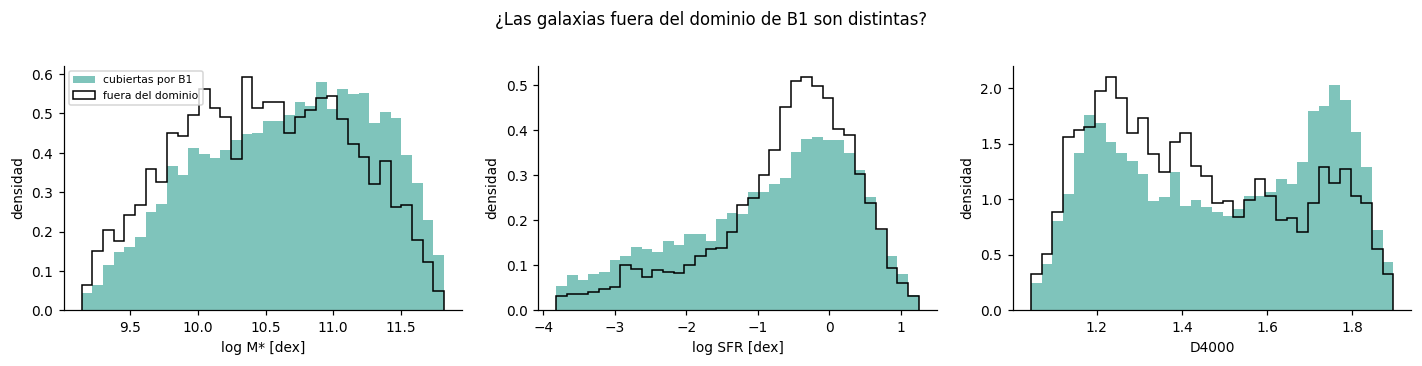

In [5]:
NOMBRE_NSA = "tabla_maestra_sdss_nsa.csv"
def _buscar_nsa():
    for p in (BASE / "entregable3_insumos" / NOMBRE_NSA, BASE / NOMBRE_NSA):
        if p.is_file():
            return p
    for patron in (f"*/{NOMBRE_NSA}", f"*/*/{NOMBRE_NSA}"):
        p = next((q for q in BASE.glob(patron) if q.is_file()), None)
        if p is not None:
            return p
    return None
RUTA_NSA = _buscar_nsa()
print("Fotometría integrada:", RUTA_NSA)
assert RUTA_NSA is not None, f"No se encontró {NOMBRE_NSA} en Drive (se espera en MyDrive/entregable3_insumos/)"
nsa = pd.read_csv(RUTA_NSA, dtype={"MANGAID": "string"})
nsa = nsa.assign(mangaid=nsa.MANGAID.str.strip()).drop_duplicates("mangaid")
num = lambda c: pd.to_numeric(nsa[c], errors="coerce")
nsa = pd.DataFrame({"mangaid": nsa.mangaid, "M_g": num("Mabs_g_corr"), "M_r": num("Mabs_r_corr"), "M_i": num("Mabs_i_corr"),
                    "b_a": num("NSA_SERSIC_BA"), "masa_nsa": num("NSA_SERSIC_MASS")})
cohorte = cohorte.drop(columns=[c for c in nsa.columns if c != "mangaid"], errors="ignore").merge(nsa, on="mangaid", how="left")
cohorte["g_i"] = cohorte.M_g - cohorte.M_i
cohorte["logM_nsa"] = np.log10(cohorte.masa_nsa.where(cohorte.masa_nsa > 0)) - 2 * np.log10(H_NSA)
cohorte["inclinacion"] = np.degrees(np.arccos(cohorte.b_a.clip(0, 1)))

mags = cohorte[["M_g", "M_r", "M_i"]]
pasos = [("Con imagen y etiquetas", np.ones(len(cohorte), bool)),
         ("Asociada al NSA, con masa NSA", np.isfinite(cohorte.logM_nsa)),
         ("Magnitudes g, r, i finitas", np.isfinite(mags).all(1)),
         (f"Magnitudes entre {MAG_MIN:g} y {MAG_MAX:g}", mags.ge(MAG_MIN).all(1) & mags.le(MAG_MAX).all(1)),
         (f"Inclinación ≤ {INCL_MAX:g}°", cohorte.inclinacion.le(INCL_MAX))]
vigente = np.ones(len(cohorte), bool)
filas = []
for nombre, cond in pasos:
    vigente = vigente & np.asarray(cond, bool)
    filas.append({"requisito": nombre, **{p: int(vigente[IDX[p]].sum()) for p in IDX}})
cohorte["cubierta"] = vigente
COB = pd.DataFrame(filas).set_index("requisito")
COB.loc["Cobertura de B1"] = [f"{100 * cohorte.cubierta.iloc[IDX[p]].mean():.0f} %" for p in IDX]
display(COB)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, t in zip(ax, OBJETIVOS):
    b = np.linspace(*np.nanpercentile(cohorte[t], [0.5, 99.5]), 35)
    a.hist(cohorte.loc[cohorte.cubierta, t], b, density=True, alpha=0.6, color=COLOR["B1"], label="cubiertas por B1")
    a.hist(cohorte.loc[~cohorte.cubierta, t], b, density=True, histtype="step", lw=1.5, color="k", label="fuera del dominio")
    a.set(xlabel=NOMBRES[t], ylabel="densidad")
ax[0].legend(fontsize=7); plt.suptitle("¿Las galaxias fuera del dominio de B1 son distintas?", y=1.02); plt.tight_layout(); plt.show()

B1 depende de mediciones que no existen para todas las galaxias, así que revisamos cuántas puede estimar y si las que quedan fuera son de algún tipo en particular. B1 cubre el 72 % de las galaxias de entrenamiento, el 71 % de las de validación y el 69 % de las de prueba. La mayoría de las galaxias excluidas se pierden por dos razones: unas 900 galaxias de entrenamiento (13 %) no tienen las tres magnitudes corregidas, y otras 1,000 (14 %) están inclinadas más de 70°.

Las galaxias excluidas no son una muestra al azar: en promedio tienen un poco menos de masa, más formación estelar y un D4000 más bajo. Tiene sentido, porque la mayoría de las galaxias vistas de canto son espirales que todavía forman estrellas. En consecuencia, las galaxias que cubre B1 son, en proporción, algo más masivas y más viejas que la muestra completa. Por eso, siempre que comparamos a B1 con otro modelo, lo hacemos con las mismas galaxias.

### 4.4 Las etiquetas

La gráfica de la SFR contra la masa estelar (el plano SFR–M\*) resume la física que el modelo debe aprender. Las galaxias formadoras siguen una secuencia en la que la SFR crece con la masa. Las apagadas son más viejas (D4000 alto), forman muy pocas estrellas y quedan por debajo de esa secuencia. Esta división en dos grupos influye en la elección de la métrica (sección 5).

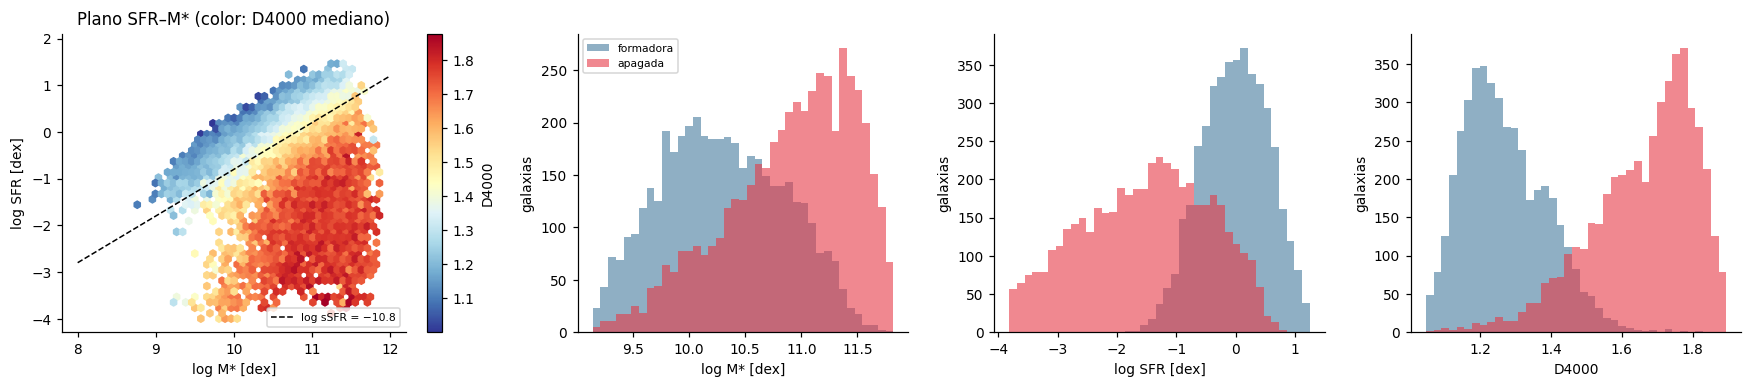

,log M* [dex],log SFR [dex],D4000
σ de la etiqueta (entrenamiento),0.647,1.161,0.243
error típico de Pipe3D (mediana),0.076,0.076,0.016
"error de Pipe3D, percentil 90",0.092,0.110,0.038


In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
hb = ax[0].hexbin(cohorte.log_mstar, cohorte.log_sfr, C=cohorte.d4000, reduce_C_function=np.median, gridsize=45,
                  cmap="RdYlBu_r", mincnt=2)
m = np.linspace(8, 12, 10); ax[0].plot(m, m + CORTE_SSFR, "k--", lw=1, label="log sSFR = −10.8")
ax[0].set(xlabel=NOMBRES["log_mstar"], ylabel=NOMBRES["log_sfr"], title="Plano SFR–M* (color: D4000 mediano)")
plt.colorbar(hb, ax=ax[0], label="D4000"); ax[0].legend(fontsize=7, loc="lower right")
for a, t in zip(ax[1:], OBJETIVOS):
    b = np.linspace(*np.percentile(cohorte[t], [0.5, 99.5]), 40)
    for pob, c in (("formadora", "#457b9d"), ("apagada", "#e63946")):
        a.hist(cohorte.loc[cohorte.poblacion == pob, t], b, alpha=0.6, color=c, label=pob)
    a.set(xlabel=NOMBRES[t], ylabel="galaxias")
ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

err = {"log_mstar": "error_log_mstar", "log_sfr": "error_log_sfr", "d4000": "error_d4000"}
ET = pd.DataFrame({NOMBRES[t]: {
    "σ de la etiqueta (entrenamiento)": cohorte[t].iloc[IDX["Train"]].std(),
    "error típico de Pipe3D (mediana)": cohorte[err[t]].median(),
    "error de Pipe3D, percentil 90": cohorte[err[t]].quantile(0.9)} for t in OBJETIVOS})
display(ET.round(3))
RUIDO = {t: float(cohorte[err[t]].median()) for t in OBJETIVOS}
SIGMA = {t: float(cohorte[t].iloc[IDX["Validation"]].std()) for t in OBJETIVOS}

La gráfica muestra con claridad los dos tipos de galaxia. Las formadoras ocupan una franja que sube desde log M\* ≈ 9.5 y log SFR ≈ −1 hasta log M\* ≈ 11.5 y log SFR ≈ 1, y tienen un D4000 bajo (en azul). Las apagadas quedan por debajo de la línea punteada (log sSFR = −10.8), tienen un D4000 alto (en rojo) y su SFR llega hasta −4. Los dos grupos tienen casi el mismo tamaño (53 % de galaxias apagadas en entrenamiento), pero ocupan intervalos de masa distintos: las formadoras predominan por debajo de log M\* ≈ 10.5 y las apagadas por encima. El D4000 también se divide en dos grupos, con picos en 1.2 y 1.75 y un mínimo cerca de 1.45.

Las etiquetas tampoco son exactas. Pipe3D reporta un error típico de 0.076 dex en masa y en SFR, y de 0.016 en D4000. Incluso un modelo que acertara el valor verdadero de cada galaxia mostraría esa diferencia frente a la etiqueta, así que ese error es el mínimo que se le puede pedir a cualquier modelo. En la SFR de las galaxias apagadas este mínimo es optimista, porque su formación estelar se mide a partir de una señal muy débil. Los dos grupos de galaxias y el error de las etiquetas son las características de los datos que determinan la métrica de la siguiente sección.

## 5. Métrica

Los dos grupos de galaxias y el error conocido de las etiquetas determinan cómo debemos medir el desempeño de los modelos.

### 5.1 Métrica principal: RMSE en dex

Elegimos la **raíz del error cuadrático medio (RMSE)** por tres razones ligadas al uso del catálogo:

1. **Interpretación directa.** log M\* y log SFR están en logaritmo, así que un error de Δ dex equivale a errar por un factor 10^Δ. Un RMSE de 0.22 dex significa un error típico de un factor 1.7; uno de 0.12 dex, de un factor 1.3.
2. **Penaliza los errores grandes.** Al elevar al cuadrado, una galaxia apagada que se estima como formadora (un error de 1 a 2 dex en SFR) pesa mucho más que muchos errores pequeños. Esos errores grandes son los que confunden a los dos tipos de galaxia y deforman los estudios que se hagan con el catálogo.
3. **Comparabilidad.** Es la métrica de Katachi y de la literatura de estimación de propiedades de galaxias. Géron (2022, cap. 2) la presenta como la medida habitual en regresión y señala que da más peso a los errores grandes que el MAE.

### 5.2 Métricas complementarias

| Métrica | Definición | Para qué sirve en este problema |
|---|---|---|
| **Sesgo** | Media de (predicción − etiqueta) | Un error sistemático desplaza relaciones físicas completas, como la secuencia de formación estelar o la distribución de masas de las galaxias |
| **MAE** | Media de \|predicción − etiqueta\| | Error típico, menos sensible a los valores extremos que el RMSE |
| **σ_NMAD** | 1.4826 · mediana(\|r − mediana(r)\|) | Dispersión de la mayoría de los errores, sin que la afecten los casos extremos; es la medida habitual en astronomía para este tipo de estimaciones (Brammer et al. 2008) |
| **Catastróficos** | Fracción con \|error\| > 0.3 dex (un factor 2) | Proporción de galaxias con errores tan grandes que cambiarían su análisis, por ejemplo al ubicarlas en el tipo de galaxia equivocado |
| **R²** | 1 − SSE/SST | Solo como referencia, porque depende de la variedad de la muestra |

### 5.3 Particularidades de los datos

Este es un problema de regresión, sin clases, pero tiene un desbalance parecido al de un problema de clasificación:

- **La SFR se divide en dos grupos.** Casi la mitad de las galaxias están apagadas, y su SFR es muy baja y difícil de medir. Un RMSE global puede verse bien aunque el modelo confunda a los dos grupos.
- **Los extremos están poco representados.** Hay pocas galaxias de masa baja y pocas muy cercanas, y son justamente las que más se alejan del promedio.

Por eso, además del valor global, reportamos las métricas **por tipo de galaxia** (formadoras y apagadas) y **por intervalo de masa**.

In [7]:
BORDES_M = [8, 9.5, 10, 10.5, 11, 12]
cohorte["bin_masa"] = pd.cut(cohorte.log_mstar, BORDES_M)
display(pd.crosstab(cohorte.bin_masa, cohorte.poblacion).rename_axis("log M*").T)

def evaluar(y, p, t):
    return DG.metricas(y, p, UMBRAL_CATASTROFICO if t != "d4000" else None)

def tabla(modelos, idx, mascara=None, ic=True):
    # Métricas de varios modelos sobre las mismas galaxias. modelos: {nombre: predicciones (N, 3)}.
    sel = idx if mascara is None else idx[mascara[idx]]
    filas = []
    for nombre, P in modelos.items():
        for k, t in enumerate(OBJETIVOS):
            y, p = Y[sel, k], P[sel, k]
            ok = np.isfinite(p)
            m = evaluar(y[ok], p[ok], t)
            f = {"modelo": nombre, "propiedad": CORTO[t], **m}
            if ic:
                lo, hi = DG.rmse_ic(y[ok], p[ok], n=N_BOOT)
                f["IC 95 %"] = f"[{lo:.3f}, {hi:.3f}]"
            filas.append(f)
    return pd.DataFrame(filas)

def ordenar(df, niveles):
    # Orden de lectura: propiedad (M*, SFR, D4000) y modelo (Piso, B1, Katachi, B2, semillas).
    orden = {"galaxias": ["todas", "cubiertas por B1"], "propiedad": ["M*", "SFR", "D4000"], "modelo": ["Piso", "B1", "Katachi", "B2"] + [f"B2 semilla {s}" for s in SEMILLAS]}
    d = df.copy()
    for c in niveles:
        if c in orden:
            d[c] = pd.Categorical(d[c], [v for v in orden[c] if v in set(d[c])], ordered=True)
    return d.sort_values(niveles).set_index(niveles)

def veredicto(lo, hi, margen):
    if hi < 0:
        return "mejor"
    if lo > 0:
        return "peor"
    if -margen < lo and hi < margen:
        return "equivalente"
    return "no concluyente"

log M*,"(8.0, 9.5]","(9.5, 10.0]","(10.0, 10.5]","(10.5, 11.0]","(11.0, 12.0]"
poblacion,,,,,
apagada,79,360,707,1298,2443
formadora,359,1096,1347,1070,544


La tabla muestra que la masa y el tipo de galaxia están muy relacionados. Entre las galaxias de menor masa (log M\* ≤ 9.5) hay 359 formadoras y solo 79 apagadas; entre las de mayor masa (log M\* > 11) hay 2,443 apagadas y 544 formadoras. Las galaxias de menor masa son apenas el 5 % de la muestra. Un modelo puede tener un error global bajo y equivocarse mucho con ellas sin que se note en el promedio. Por eso, en las secciones 9 y 10 reportamos el error por tipo de galaxia y por intervalo de masa.

## 6. Desempeño mínimo

Con la métrica definida, falta fijar el valor que un modelo debe alcanzar para considerarse aceptable. El problema tiene antecedentes, así que el desempeño mínimo no se fija de forma arbitraria. Reunimos cuatro referencias:

| Referencia | Qué representa |
|---|---|
| **σ de la etiqueta** | El error del modelo que predice siempre el promedio. Un modelo útil debe estar claramente por debajo |
| **Katachi publicado** (Alfonzo et al. 2024) | El desempeño histórico al estimar estas mismas etiquetas desde imágenes, con SDSS |
| **Precisión típica de las masas estelares**: 0.10–0.15 dex | La diferencia típica entre las masas que obtienen distintos métodos establecidos, ya sea a partir del color o del ajuste de la distribución espectral de energía (Roediger y Courteau 2015) |
| **Error de las etiquetas** (Pipe3D) | El límite inferior alcanzable |

Con ellas fijamos los criterios **antes** de evaluar los modelos y los guardamos en `criterios.json`:

| Criterio | Condición | Sobre |
|---|---|---|
| **Viabilidad** | Todo el intervalo de confianza del 95 % del RMSE queda por debajo del RMSE del modelo que predice el promedio, en las mismas galaxias | B1 y B2, en cada propiedad |
| **Desempeño mínimo del baseline** | B2 no es peor que Katachi por más del margen tolerado: el límite superior del intervalo de la diferencia RMSE(B2) − RMSE(Katachi) es menor que 0.02 dex en masa y SFR, y que 0.01 en D4000 | B2 frente a Katachi en las mismas galaxias de prueba, con las tres semillas |
| **Desempeño deseable en masa** | RMSE ≤ 0.15 dex | B2, masa estelar |

In [8]:
REF = pd.DataFrame({CORTO[t]: {"σ de la etiqueta (validación)": SIGMA[t], "Katachi publicado (prueba)": KATACHI_PUBLICADO[t],
                               "Precisión típica de las masas": MASA_DESEABLE if t == "log_mstar" else np.nan,
                               "Error de la etiqueta (Pipe3D)": RUIDO[t]} for t in OBJETIVOS})
display(REF.round(3))
CRITERIOS = {"viabilidad": "IC95 superior del RMSE < RMSE del piso en las mismas galaxias", "minimo": "IC95 superior de ΔRMSE(B2 − Katachi) < margen",
             "deseable_masa": MASA_DESEABLE, "margen": MARGEN, "sigma": SIGMA, "katachi_publicado": KATACHI_PUBLICADO,
             "semillas": SEMILLAS, "fecha_utc": datetime.now(timezone.utc).isoformat(), "commit": COMMIT}
f_crit = RES / "criterios.json"
if f_crit.exists():
    anterior = json.loads(f_crit.read_text())
    assert all(anterior[k] == json.loads(json.dumps(CRITERIOS[k])) for k in ("viabilidad", "minimo", "deseable_masa", "margen")), \
        "Los criterios cambiaron después de registrarse"
    print("Criterios registrados el", anterior["fecha_utc"])
else:
    guard.write_json(f_crit, CRITERIOS)
    print("Criterios registrados en", f_crit)

,M*,SFR,D4000
σ de la etiqueta (validación),0.656,1.164,0.236
Katachi publicado (prueba),0.222,0.668,0.100
Precisión típica de las masas,0.150,NaN,NaN
Error de la etiqueta (Pipe3D),0.076,0.076,0.016


Criterios registrados el 2026-10-18T15:21:00.526122+00:00


## 7. Algoritmos y resultados en validación

Con los criterios registrados, pasamos a los modelos. Primero justificamos cada algoritmo y después los evaluamos en las galaxias de validación.

### 7.1 Por qué estos algoritmos

El tipo de dato define el algoritmo. B1 trabaja con **datos estructurados** de dos variables con una relación física conocida; B2, con **datos no estructurados**: imágenes de tres bandas.

| Criterio | Regresión lineal (B1 en masa) | Bosque aleatorio sobre las mismas variables (B1 en SFR y D4000) | Red desde cero | **ResNet50 con transferencia (B2)** | Transformadores de visión o modelos fundacionales |
|---|---|---|---|---|---|
| Tipo de datos | Tabular | Tabular | Imagen | **Imagen** | Imagen |
| Cantidad de datos (7,123 galaxias) | Suficiente: 2 parámetros | Suficiente | Insuficiente para aprender filtros desde cero | **Suficiente: reutiliza filtros aprendidos en ImageNet** (Géron 2022, cap. 14) | Requieren más datos o un preentrenamiento astronómico; son candidatos para la siguiente fase |
| Relaciones no lineales | No | Sí | Sí | **Sí** | Sí |
| Estructura espacial (bulbo, disco, brazos) | No la ve | No la ve | Sí | **Sí; reconoce un patrón sin importar en qué parte de la imagen esté** | Sí |
| Interpretabilidad | **Máxima: coeficientes con significado físico** | Importancias | Baja | Media: oclusión y SHAP | Baja |
| Antecedente publicado | Taylor et al. (2011) | — | — | **Katachi** (Alfonzo et al. 2024) | Parcial |
| Costo | Segundos | Segundos | Horas | **~25 min por semilla en una A100** | Mayor |

**B1** usa la forma de Taylor et al. (2011). La masa es el producto de la luminosidad por el cociente masa–luminosidad (M/L), y el M/L depende del color:

log M\* = log(M/L) + log L = A + B (g − i) − 0.4 Mᵢ

El término −0.4 Mᵢ convierte la magnitud absoluta en luminosidad (es la definición de magnitud), así que **su coeficiente está fijo**: solo se ajustan A y B. En la práctica, ajustamos una recta entre log M\* + 0.4 Mᵢ y el color g − i. Para la SFR y el D4000 no existe una relación equivalente, así que comparamos una regresión lineal con las mismas dos variables y un bosque aleatorio (Breiman 2001), que capta relaciones no lineales sin necesidad de escalar las variables. En masa también probamos un bosque con el mismo término fijo, para comprobar si la relación con el color es realmente lineal. En cada propiedad elegimos el modelo más simple cuyo error de validación cruzada no supera al mínimo en más de un error estándar (Hastie et al. 2009, §7.10).

**B2** es la cadena de Katachi: tres ResNet50 (He et al. 2016) preentrenadas en ImageNet que estiman, en orden, la masa, la SFR y el D4000. Cada red recibe la imagen y, como canales adicionales con un valor constante, las predicciones de las redes anteriores, porque la SFR y la edad de una galaxia dependen de su masa.

### 7.2 B1: relación color–masa

Primero comparamos los coeficientes de Taylor con los que resultan al ajustar la relación con dos masas distintas: la del NSA, que se calculó con las mismas magnitudes que usa B1, y la de Pipe3D, que se midió con el espectro y es la etiqueta del proyecto.

,A,B,RMSE frente a NSA,RMSE frente a Pipe3D
ajustada con masa NSA,1.785,0.423,0.066,0.202
ajustada con masa Pipe3D,2.058,0.235,0.152,0.153
"Taylor et al. (2011), publicada",1.150,0.700,0.430,0.576


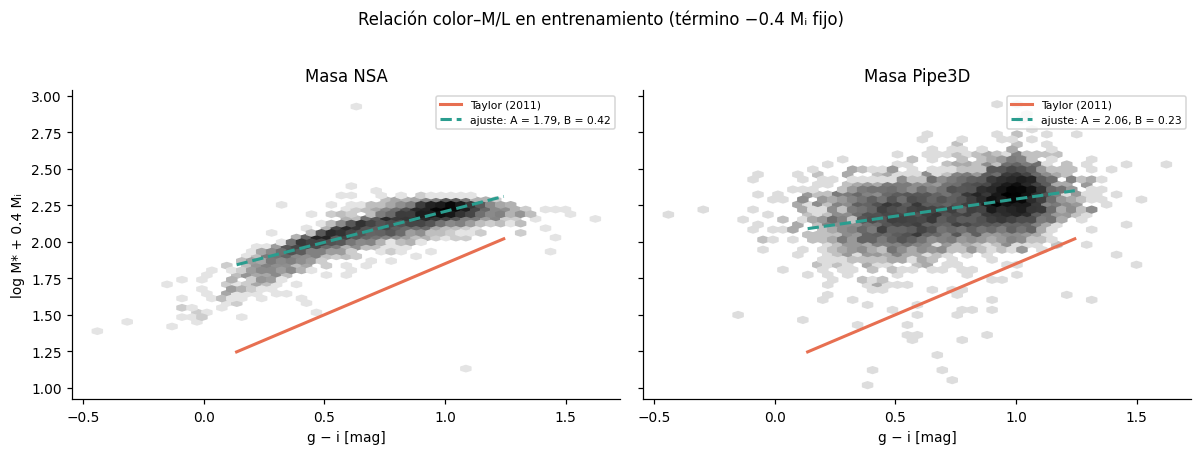

In [9]:
cub = cohorte.cubierta.to_numpy()
TRc, VAc = IDX["Train"][cub[IDX["Train"]]], IDX["Validation"][cub[IDX["Validation"]]]
GI, MI = cohorte.g_i.to_numpy(), cohorte.M_i.to_numpy()

def ajustar_b1(modelo, t, idx, seed=SEMILLA, objetivo=None):
    # Devuelve una función pred(gi, Mi). En masa, el término −0.4 Mi es fijo.
    y = (cohorte[t] if objetivo is None else objetivo).to_numpy()[idx]
    masa = t == "log_mstar"
    if modelo == "Taylor":
        return lambda gi, mi: TAYLOR[0] + TAYLOR[1] * gi - 0.4 * mi
    X = (GI[idx, None] if masa else np.c_[GI[idx], MI[idx]])
    yy = y + 0.4 * MI[idx] if masa else y
    est = (LinearRegression() if modelo == "Lineal" else
           RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=seed, n_jobs=-1)).fit(X, yy)
    if masa:
        f = lambda gi, mi: est.predict(np.asarray(gi)[:, None]) - 0.4 * np.asarray(mi)
    else:
        f = lambda gi, mi: est.predict(np.c_[gi, mi])
    f.est = est
    return f

coef = {}
for nombre, objetivo in (("NSA", cohorte.logM_nsa), ("Pipe3D", cohorte.log_mstar)):
    lr = ajustar_b1("Lineal", "log_mstar", TRc, objetivo=objetivo).est
    p = lr.predict(GI[VAc, None]) - 0.4 * MI[VAc]
    for etiqueta, yv in (("NSA", cohorte.logM_nsa.to_numpy()[VAc]), ("Pipe3D", Y[VAc, 0])):
        coef.setdefault(f"ajustada con masa {nombre}", {"A": lr.intercept_, "B": lr.coef_[0]})[f"RMSE frente a {etiqueta}"] = \
            DG.metricas(yv, p)["RMSE"]
pt = TAYLOR[0] + TAYLOR[1] * GI[VAc] - 0.4 * MI[VAc]
coef["Taylor et al. (2011), publicada"] = {"A": TAYLOR[0], "B": TAYLOR[1],
                                           "RMSE frente a NSA": DG.metricas(cohorte.logM_nsa.to_numpy()[VAc], pt)["RMSE"],
                                           "RMSE frente a Pipe3D": DG.metricas(Y[VAc, 0], pt)["RMSE"]}
COEF = pd.DataFrame(coef).T[["A", "B", "RMSE frente a NSA", "RMSE frente a Pipe3D"]]
display(COEF.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
gx = np.linspace(np.nanpercentile(GI[TRc], 1), np.nanpercentile(GI[TRc], 99), 10)
for a, (nombre, col) in zip(ax, (("NSA", "logM_nsa"), ("Pipe3D", "log_mstar"))):
    yy = cohorte[col].to_numpy()[TRc] + 0.4 * MI[TRc]
    a.hexbin(GI[TRc], yy, gridsize=50, cmap="Greys", mincnt=1, norm=mcolors.LogNorm(vmin=0.3))
    a.plot(gx, TAYLOR[0] + TAYLOR[1] * gx, color=COLOR["Katachi"], lw=2, label="Taylor (2011)")
    f = coef[f"ajustada con masa {nombre}"]
    a.plot(gx, f["A"] + f["B"] * gx, color=COLOR["B1"], lw=2, ls="--", label=f"ajuste: A = {f['A']:.2f}, B = {f['B']:.2f}")
    a.set(xlabel="g − i [mag]", title=f"Masa {nombre}"); a.legend(fontsize=7)
ax[0].set_ylabel("log M* + 0.4 Mᵢ"); plt.suptitle("Relación color–M/L en entrenamiento (término −0.4 Mᵢ fijo)", y=1.02)
plt.tight_layout(); plt.show()

Los coeficientes publicados por Taylor no funcionan directamente con estas magnitudes: la recta queda unos 0.6 dex por debajo de las galaxias en las dos gráficas, y su error es de 0.43 dex frente a la masa del NSA y de 0.58 frente a la de Pipe3D. Esto se debe a que el término constante A depende de convenciones que cambian entre catálogos, como el valor de la constante de Hubble con el que se expresan magnitudes y masas, el punto cero de las magnitudes y la suposición sobre cuántas estrellas de cada masa se forman (la función inicial de masa). Un cambio de convención desplaza todas las masas en la misma cantidad. Por eso volvemos a ajustar los coeficientes con nuestros datos.

Ajustada con la masa del NSA, la relación reproduce esa masa con un error de solo 0.066 dex. Sin embargo, este resultado no mide la capacidad de predecir, porque el NSA calculó su masa con las mismas magnitudes: la relación casi repite el cálculo del catálogo. Si usamos esa misma relación para estimar la masa de Pipe3D, que se midió de forma independiente, el error sube a 0.202 dex. Ajustada directamente con la masa de Pipe3D, la relación tiene una pendiente menor (B = 0.23 en lugar de 0.42) y llega a 0.153 dex. Es decir, con solo dos números por galaxia ya se estima la masa medida con el espectro con un error típico de un factor 1.4. La nube de puntos de Pipe3D es más ancha que la del NSA, como se espera de una medición hecha con otra técnica.

Ahora ajustamos las variantes de B1 para las tres propiedades y las comparamos con validación cruzada de 5 particiones dentro de entrenamiento, repetida con las tres semillas.

In [10]:
VARIANTES = {"log_mstar": ["Taylor", "Lineal", "Árboles"], "log_sfr": ["Lineal", "Árboles"], "d4000": ["Lineal", "Árboles"]}
filas = []
for k, t in enumerate(OBJETIVOS):
    for v in VARIANTES[t]:
        errs = []
        for s in SEMILLAS:
            for a, b in KFold(5, shuffle=True, random_state=s).split(TRc):
                f = ajustar_b1(v, t, TRc[a], seed=s)
                errs.append(DG.metricas(Y[TRc[b], k], f(GI[TRc[b]], MI[TRc[b]]))["RMSE"])
        filas.append({"propiedad": CORTO[t], "variante": v, "RMSE CV": np.mean(errs),
                      "error estándar": np.std(errs, ddof=1) / np.sqrt(len(errs)), "parámetros": {"Taylor": 0, "Lineal": 2 if k == 0 else 3}.get(v, "—")})
CV_B1 = pd.DataFrame(filas)
ELECCION_B1 = {}
for t in OBJETIVOS:
    d = CV_B1[(CV_B1.propiedad == CORTO[t]) & (CV_B1.variante != "Taylor")].set_index("variante")
    limite = d["RMSE CV"].min() + d.loc[d["RMSE CV"].idxmin(), "error estándar"]
    ELECCION_B1[t] = "Lineal" if d.loc["Lineal", "RMSE CV"] <= limite else "Árboles"
CV_B1["elegida"] = [ELECCION_B1[t] == v for t, v in zip([k for k in OBJETIVOS for _ in VARIANTES[k]], CV_B1.variante)]
display(CV_B1.round(4))
print("Variante elegida por la regla de un error estándar:", {CORTO[t]: v for t, v in ELECCION_B1.items()})

B1F = {t: ajustar_b1(ELECCION_B1[t], t, TRc) for t in OBJETIVOS}
def predecir_b1(idx, gi=None, mi=None):
    P = np.full((len(cohorte), 3), np.nan)
    gi = GI[idx] if gi is None else gi
    mi = MI[idx] if mi is None else mi
    for k, t in enumerate(OBJETIVOS):
        P[idx, k] = B1F[t](gi, mi)
    return P
P_B1 = predecir_b1(np.where(cub)[0])

,propiedad,variante,RMSE CV,error estándar,parámetros,elegida
0,M*,Taylor,0.580,1.100e-03,0,False
1,M*,Lineal,0.152,1.900e-03,2,True
2,M*,Árboles,0.161,1.800e-03,—,False
3,SFR,Lineal,0.969,5.100e-03,3,False
4,SFR,Árboles,0.935,6.200e-03,—,True
5,D4000,Lineal,0.123,9.000e-04,3,False
6,D4000,Árboles,0.120,9.000e-04,—,True


Variante elegida por la regla de un error estándar: {'M*': 'Lineal', 'SFR': 'Árboles', 'D4000': 'Árboles'}


Hacemos la validación cruzada dentro de las galaxias de entrenamiento para reservar las de validación a la medición del resultado. Entre dos modelos con errores parecidos, la regla de un error estándar elige el más simple. En masa, la regresión lineal (0.152 dex) es mejor que el bosque aleatorio (0.161) y es la que se elige: la relación entre la masa corregida por la luminosidad y el color es lineal, y el bosque solo agrega variaciones que no ayudan a predecir. En la SFR y el D4000, el bosque es mejor por más de un error estándar (0.935 contra 0.969 dex, y 0.120 contra 0.123), así que se elige el bosque: estas propiedades no dependen del color de forma lineal. En el D4000 la diferencia es pequeña, aunque mayor que la incertidumbre de la estimación. En la SFR, el color y la magnitud bajan el error de 1.16 dex (el del promedio) a 0.94 dex. La mejora es modesta, porque dos valores que resumen a toda la galaxia contienen poca información sobre cuántas estrellas está formando en la actualidad.

### 7.3 B2: red convolucional

B1 muestra lo que se logra sin imágenes. B2 es el extremo opuesto: un modelo que solo ve la imagen.

| Elemento | Valor |
|---|---|
| Arquitectura | Tres ResNet50 en cadena: imagen → log M\*; imagen + canal con la M\* predicha → log SFR; imagen + canales con la M\* y la SFR predichas → D4000 |
| Inicialización | Pesos de ImageNet; capa final Linear(2048 → 1); primera capa nueva en las redes de SFR y D4000, que reciben 4 y 5 canales |
| Entrada | 300 × 300 píxeles; bandas z, r, g en el lugar de R, G, B |
| Pérdida y optimizador | MSE y Adam (tasa de aprendizaje de 10⁻³) en cada red; el error de una red no modifica a las anteriores |
| Programa | 30 épocas; la tasa de aprendizaje sube durante las 2 primeras y después baja de forma gradual (coseno); precisión mixta bf16; lotes de 32 imágenes |
| Aumentación | Rotación aleatoria de 0 a 360° en cada época |
| Predicción | Promedio de las 8 rotaciones de 90° y reflejos de cada imagen (*test-time augmentation*) |
| Semillas | 42, 7 y 2026 |

La celda siguiente entrena cada semilla. Si un entrenamiento ya existe en Drive, se reutiliza; si quedó a medias, se reanuda desde su último punto de control. Con una A100, cada semilla tarda unos 25 minutos.

In [11]:
MEJ = MejorasConfig(programa_rapido=True, epocas_rapido=EPOCAS, precision_mixta=True)
CFG = TrainConfig(fused_adam=DEVICE.type == "cuda", channels_last=DEVICE.type == "cuda", freeze_pretrained=False)
EXPS = [Experimento("base", MEJ, s, descripcion="Baseline B2") for s in SEMILLAS]
CTX = preparar_datos(cohorte, X300, NORM, fcfg, paths, guard, EXPS, tag=TAG)
t0 = time.time()
for e in EXPS:
    correr(e, CTX, paths, guard, DEVICE, base=CFG, max_epochs=EPOCAS if LIMITE else None,
           log=lambda s: print(s, flush=True))
print(f"Entrenamientos listos en {(time.time() - t0) / 60:.0f} min:", [e.identificador(fcfg.crop_px) for e in EXPS])

def cargar_red(semilla):
    e = Experimento("base", MEJ, semilla)
    t = Trainer(replace(CFG, seed=semilla), NORM, fcfg.out_px, paths.run_dir(e.identificador(fcfg.crop_px)), guard, DEVICE,
                log=lambda *_: None, mejoras=MEJ)
    t.load_final()
    return t

def datos(p):
    return GPUData(X300[IDX[p]], Y[IDX[p]].astype(np.float32), DEVICE)

P_B2 = {s: np.full((len(cohorte), 3), np.nan) for s in SEMILLAS}
REDES = {s: cargar_red(s) for s in SEMILLAS}
for p in ("Train", "Validation"):
    D = datos(p)
    for s, red in REDES.items():
        P_B2[s][IDX[p]] = red.predict(D, tta=True)
    del D
for s in SEMILLAS:
    pd.DataFrame({"mangaid": cohorte.mangaid, "particion": cohorte.particion,
                  **{f"pred_{t}": P_B2[s][:, k] for k, t in enumerate(OBJETIVOS)}}).query("particion != 'Test'") \
      .pipe(lambda d: guard.write(RES / f"predicciones_B2_seed{s}.csv", lambda f: d.to_csv(f, index=False), allow_replace=True))

[datos] Train 7123 · Validation 1262 · caché con margen: no · σ por imagen: no
[base] ya terminado · se reutiliza X_base_recorte300_completo_bf16_rapido30_seed42
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 202MB/s]


epoch=1 train_loss_mstar=2.601 train_loss_sfr=1.061 train_loss_d4000=0.05708 val_loss_mstar=0.1414 val_loss_sfr=1.464 val_loss_d4000=0.03927 lr_mstar=0.001 lr_sfr=0.001 lr_d4000=0.001 seconds=60.15
epoch=2 train_loss_mstar=0.1132 train_loss_sfr=0.8112 train_loss_d4000=0.02626 val_loss_mstar=0.1186 val_loss_sfr=0.694 val_loss_d4000=0.01882 lr_mstar=0.001 lr_sfr=0.001 lr_d4000=0.001 seconds=37.25
epoch=3 train_loss_mstar=0.09901 train_loss_sfr=0.739 train_loss_d4000=0.0225 val_loss_mstar=0.1492 val_loss_sfr=0.9244 val_loss_d4000=0.02795 lr_mstar=0.0009969 lr_sfr=0.0009969 lr_d4000=0.0009969 seconds=37.26
epoch=4 train_loss_mstar=0.09004 train_loss_sfr=0.6806 train_loss_d4000=0.02225 val_loss_mstar=0.06306 val_loss_sfr=1.365 val_loss_d4000=0.0415 lr_mstar=0.0009875 lr_sfr=0.0009875 lr_d4000=0.0009875 seconds=36.72
epoch=5 train_loss_mstar=0.09224 train_loss_sfr=0.6778 train_loss_d4000=0.0179 val_loss_mstar=0.103 val_loss_sfr=1.363 val_loss_d4000=0.06352 lr_mstar=0.0009719 lr_sfr=0.0009719

### 7.4 Comparación de los modelos en validación

Comparamos los modelos en las galaxias de validación. B1 solo cubre una parte, así que la tabla tiene dos bloques: todas las galaxias (el promedio y B2) y las cubiertas por B1 (los tres modelos sobre las mismas galaxias). Para B2 se muestra la semilla principal con su intervalo, y la media y la desviación entre las tres semillas.

N   RMSE         IC 95 % RMSE 3 semillas  sesgo  sigma_NMAD  catastroficos         R2
galaxias         propiedad modelo                                                                                          
todas            M*        Piso    1262  0.656  [0.635, 0.676]                  0.009       0.763          0.697 -1.814e-04
                           B2      1262  0.219  [0.206, 0.232]   0.218 ± 0.001 -0.013       0.187          0.140  8.882e-01
                 SFR       Piso    1262  1.164  [1.119, 1.204]                  0.018       1.084          0.811 -2.515e-04
                           B2      1262  0.611  [0.576, 0.642]   0.615 ± 0.006 -0.022       0.462          0.526  7.248e-01
                 D4000     Piso    1262  0.236  [0.230, 0.241]                  0.003       0.327            NaN -1.270e-04
                           B2      1262  0.073  [0.069, 0.077]   0.073 ± 0.000 -0.002       0.062            NaN  9.047e-01
cubiertas por B1 M*        Piso     899  0.647  [0.625, 0.668]                 -0.052       0.742          0.701 -6.470e-03
                           B1       899  0.153  [0.142, 0.166]                  0.001       0.134          0.040  9.437e-01
                           B2       899  0.212  [0.196, 0.226]   0.210 ± 0.001 -0.007       0.187          0.122  8.923e-01
                 SFR       Piso     899  1.201  [1.147, 1.252]                  0.071       1.180          0.821 -3.509e-03
                           B1       899  0.962  [0.906, 1.016]                 -0.010       0.684          0.628  3.559e-01
                           B2       899  0.624  [0.587, 0.664]   0.629 ± 0.004 -0.006       0.474          0.544  7.289e-01
                 D4000     Piso     899  0.240  [0.233, 0.246]                 -0.016       0.334            NaN -4.377e-03
                           B1       899  0.123  [0.116, 0.130]                  0.004       0.107            NaN  7.373e-01
                           B2       899  0.073  [0.068, 0.079]   0.073 ± 0.000 -0.006       0.059            NaN  9.059e-01

ΔRMSE (B2 − B1)           IC 95 % veredicto para B2
propiedad semilla                                                     
M*        42                 0.059  [+0.042, +0.075]              peor
          7                  0.057  [+0.039, +0.073]              peor
          2026               0.056  [+0.039, +0.072]              peor
SFR       42                -0.338  [-0.382, -0.290]             mejor
          7                 -0.329  [-0.375, -0.282]             mejor
          2026              -0.332  [-0.378, -0.283]             mejor
D4000     42                -0.049  [-0.056, -0.042]             mejor
          7                 -0.050  [-0.057, -0.043]             mejor
          2026              -0.050  [-0.057, -0.043]             mejor

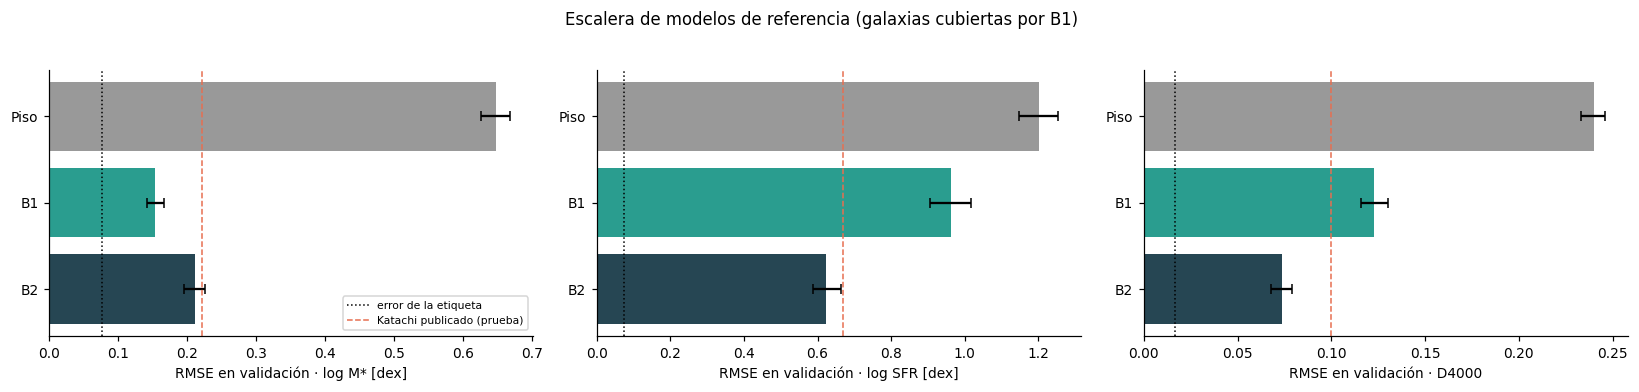

In [12]:
P_PISO = np.tile(Y[IDX["Train"]].mean(0), (len(cohorte), 1))
VA = IDX["Validation"]
bloques = []
for nombre_bloque, masc in (("todas", None), ("cubiertas por B1", cub)):
    mods = {"Piso": P_PISO, "B2": P_B2[SEMILLA]} if masc is None else {"Piso": P_PISO, "B1": P_B1, "B2": P_B2[SEMILLA]}
    tb = tabla(mods, VA, masc)
    sel = VA if masc is None else VA[masc[VA]]
    sem = {(CORTO[t]): [DG.metricas(Y[sel, k], P_B2[s][sel, k])["RMSE"] for s in SEMILLAS] for k, t in enumerate(OBJETIVOS)}
    tb["RMSE 3 semillas"] = [f"{np.mean(sem[r.propiedad]):.3f} ± {np.std(sem[r.propiedad], ddof=1):.3f}"
                             if r.modelo == "B2" and len(SEMILLAS) > 1 else "" for r in tb.itertuples()]
    tb.insert(0, "galaxias", nombre_bloque)
    bloques.append(tb)
ESCALERA = pd.concat(bloques, ignore_index=True)
display(ordenar(ESCALERA[["galaxias", "modelo", "propiedad", "N", "RMSE", "IC 95 %", "RMSE 3 semillas", "sesgo", "sigma_NMAD",
                          "catastroficos", "R2"]], ["galaxias", "propiedad", "modelo"]))

sel = VA[cub[VA]]
filas = []
for k, t in enumerate(OBJETIVOS):
    for s in SEMILLAS:
        d, lo, hi = DG.delta_rmse(Y[sel, k], P_B2[s][sel, k], P_B1[sel, k], n=N_BOOT)
        filas.append({"propiedad": CORTO[t], "semilla": s, "ΔRMSE (B2 − B1)": d, "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]",
                      "veredicto para B2": veredicto(lo, hi, MARGEN[t])})
display(pd.DataFrame(filas).set_index(["propiedad", "semilla"]).round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for a, t in zip(ax, OBJETIVOS):
    r = ESCALERA[(ESCALERA.galaxias == "cubiertas por B1") & (ESCALERA.propiedad == CORTO[t])]
    ic = np.array([[float(v) for v in s.strip("[]").split(",")] for s in r["IC 95 %"]])
    a.barh(r.modelo, r.RMSE, xerr=np.abs(ic.T - r.RMSE.to_numpy()), color=[COLOR[m] for m in r.modelo], capsize=3)
    a.axvline(RUIDO[t], color="k", ls=":", lw=1, label="error de la etiqueta")
    a.axvline(KATACHI_PUBLICADO[t], color=COLOR["Katachi"], ls="--", lw=1, label="Katachi publicado (prueba)")
    a.set(xlabel=f"RMSE en validación · {NOMBRES[t]}"); a.invert_yaxis()
ax[0].legend(fontsize=7, loc="lower right"); plt.suptitle("Escalera de modelos de referencia (galaxias cubiertas por B1)", y=1.03)
plt.tight_layout(); plt.show()

Los dos modelos tienen errores mucho menores que el del promedio en las tres propiedades. En todas las galaxias de validación, B2 reduce ese error en 67 % en masa (0.219 contra 0.656 dex), en 48 % en SFR (0.611 contra 1.164) y en 69 % en D4000 (0.073 contra 0.236). Las tres semillas dan prácticamente el mismo resultado (0.218 ± 0.001, 0.615 ± 0.006 y 0.073 ± 0.000), así que el desempeño no depende de una inicialización afortunada.

Cuando comparamos a B1 y B2 en las mismas galaxias, el mejor modelo depende de la propiedad, y el resultado es el mismo con las tres semillas. En la masa, B1 tiene un error menor que B2 (0.153 contra 0.212 dex). La razón es que la magnitud absoluta que usa B1 ya toma en cuenta la distancia a la galaxia, mientras que la imagen no da esa información: una galaxia pequeña y cercana puede verse igual que una grande y lejana. En la SFR y el D4000 sucede lo contrario y B2 es mucho mejor (0.624 contra 0.962 dex, y 0.073 contra 0.123). La imagen muestra cómo se distribuyen la luz y el color dentro de la galaxia, y esa distribución contiene información sobre la formación de estrellas y la edad que no tienen dos valores que resumen a toda la galaxia.

En validación, B2 ya tiene un error menor que el publicado por Katachi en SFR y D4000, y uno similar en masa, aunque esas cifras de Katachi se midieron en otras galaxias (las de prueba); la comparación directa, con las mismas galaxias, se hace en la sección 10. Aun así, todos los errores siguen muy por encima del error de las etiquetas, así que hay espacio para modelos mejores. La siguiente sección analiza qué información usa cada modelo para llegar a estos resultados.

## 8. Importancia de las características

La sección anterior mostró cuánto acierta cada modelo; esta sección busca por qué. En B1, las características son dos variables, y su importancia se mide con los coeficientes y con permutación. En B2, las "características" son las bandas de la imagen, las regiones de la galaxia y las predicciones que una red le pasa a la siguiente. Usamos cuatro métodos, todos medidos en las galaxias de validación:

| Método | Tipo | Qué responde |
|---|---|---|
| Coeficientes y permutación en B1 | Embebido y por permutación | ¿Cuánto aportan el color y la luminosidad? |
| Oclusión de bandas en B2 | Eliminación de una entrada (similar a la permutación) | ¿Qué banda usa la red para cada propiedad? |
| Oclusión radial en B2 | Eliminación de una entrada | ¿Qué región de la galaxia (núcleo o afueras) contiene la información? |
| Permutación de las predicciones de la cadena | Permutación | ¿Cuánto depende cada red de la predicción anterior? |
| Mapas SHAP (Lundberg y Lee 2017) | Atribución por píxel | ¿Qué píxeles suben o bajan cada predicción, y cómo cambia entre tipos de galaxia? |

Medimos la importancia de cada elemento como el **aumento del RMSE** cuando el modelo deja de recibir esa información, con su intervalo de confianza.

### 8.1 B1: color frente a luminosidad

,coef. g − i,coef. Mᵢ,efecto de 1σ de g − i,efecto de 1σ de Mᵢ
propiedad,,,,
M*,0.235,-0.4,0.062,-0.638


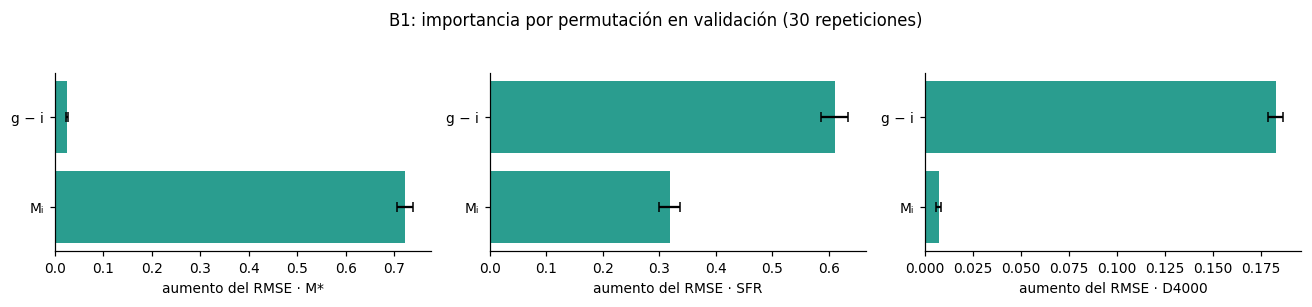

In [13]:
rng = np.random.default_rng(SEMILLA)
filas = []
base_va = predecir_b1(VAc)
for k, t in enumerate(OBJETIVOS):
    for var in ("g − i", "Mᵢ"):
        deltas = []
        for rep in range(30):
            pi = rng.permutation(len(VAc))
            gi, mi = GI[VAc].copy(), MI[VAc].copy()
            if var == "g − i":
                gi = gi[pi]
            else:
                mi = mi[pi]
            pp = B1F[t](gi, mi)
            deltas.append(DG.metricas(Y[VAc, k], pp)["RMSE"] - DG.metricas(Y[VAc, k], base_va[VAc, k])["RMSE"])
        filas.append({"propiedad": CORTO[t], "variable": var, "ΔRMSE": np.mean(deltas), "desv.": np.std(deltas)})
IMP_B1 = pd.DataFrame(filas)
lin = {t: (B1F[t].est if hasattr(B1F[t], "est") else None) for t in OBJETIVOS}
filas = []
for t in OBJETIVOS:
    e = lin[t]
    if isinstance(e, LinearRegression):
        sd = [np.std(GI[TRc])] + ([np.std(MI[TRc])] if t != "log_mstar" else [])
        b = list(e.coef_)
        if t == "log_mstar":
            b, sd = b + [-0.4], sd + [np.std(MI[TRc])]
        filas.append({"propiedad": CORTO[t], "coef. g − i": b[0], "coef. Mᵢ": b[1],
                      "efecto de 1σ de g − i": b[0] * sd[0], "efecto de 1σ de Mᵢ": b[1] * sd[1]})
display(pd.DataFrame(filas).set_index("propiedad").round(3))

fig, ax = plt.subplots(1, 3, figsize=(12, 2.6))
for a, t in zip(ax, OBJETIVOS):
    d = IMP_B1[IMP_B1.propiedad == CORTO[t]]
    a.barh(d.variable, d["ΔRMSE"], xerr=d["desv."], color=COLOR["B1"], capsize=3)
    a.set(xlabel=f"aumento del RMSE · {CORTO[t]}"); a.invert_yaxis()
plt.suptitle("B1: importancia por permutación en validación (30 repeticiones)", y=1.05); plt.tight_layout(); plt.show()

La permutación consiste en revolver los valores de una variable entre las galaxias y medir cuánto empeora el modelo. En la relación color–masa, la luminosidad determina la escala de la masa y el color hace una corrección que depende de la edad y del polvo de las estrellas, y la permutación lo confirma. En la masa, revolver la magnitud aumenta el error en 0.72 dex, mientras que revolver el color lo aumenta solo en 0.02 dex. Los coeficientes dicen lo mismo: un cambio de una desviación estándar en Mᵢ cambia la masa en 0.64 dex, y uno en el color, en 0.06. En la SFR el orden se invierte: el color pesa más (0.61 dex) que la magnitud (0.32 dex), porque el color indica qué proporción de las estrellas es joven y la magnitud ubica a la galaxia en la secuencia de formación estelar. En el D4000 casi solo importa el color (0.18 contra 0.007 dex), lo que se espera de un indicador de edad.

### 8.2 B2: bandas y regiones de la imagen

Para quitar una banda, reemplazamos sus valores por el nivel del cielo (0 después de la transformación) y dejamos las otras dos sin cambios. Para quitar una región, hacemos lo mismo con las tres bandas dentro de un anillo, medido en unidades del R50 de cada galaxia. A este procedimiento se le llama oclusión. Las imágenes modificadas son distintas de las que la red vio al entrenar, así que la prueba indica **qué información usa** la red, no qué información existe en la imagen.

mean                  std              
propiedad             M*    SFR  D4000     M*    SFR  D4000
tipo   elemento                                            
banda  z           0.666  0.517  0.147  0.087  0.088  0.018
       r           0.707  0.474  0.324  0.240  0.023  0.037
       g           0.401  0.629  0.183  0.030  0.070  0.024
anillo 0–0.5       0.458  0.327  0.138  0.026  0.039  0.008
       0.5–1       0.323  0.430  0.112  0.100  0.016  0.029
       1–2         0.320  0.566  0.076  0.153  0.035  0.019
       2–4         0.349  0.367  0.037  0.273  0.057  0.013
       > 4         0.366  0.090  0.023  0.309  0.071  0.020
plano  masa→SFR    0.000  0.343  0.017  0.000  0.064  0.003
       masa→D4000  0.000  0.000  0.039  0.000  0.000  0.016
       SFR→D4000   0.000  0.000  0.057  0.000  0.000  0.016

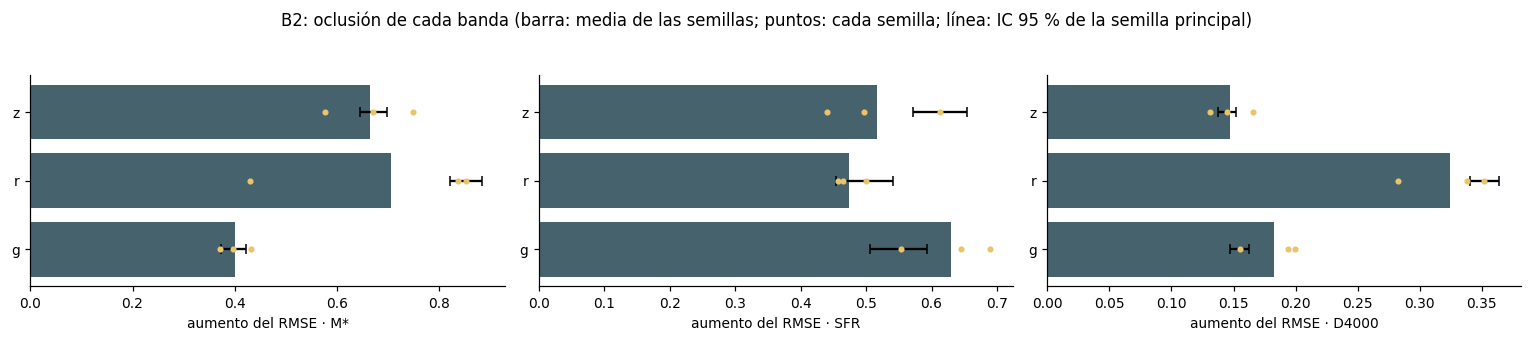

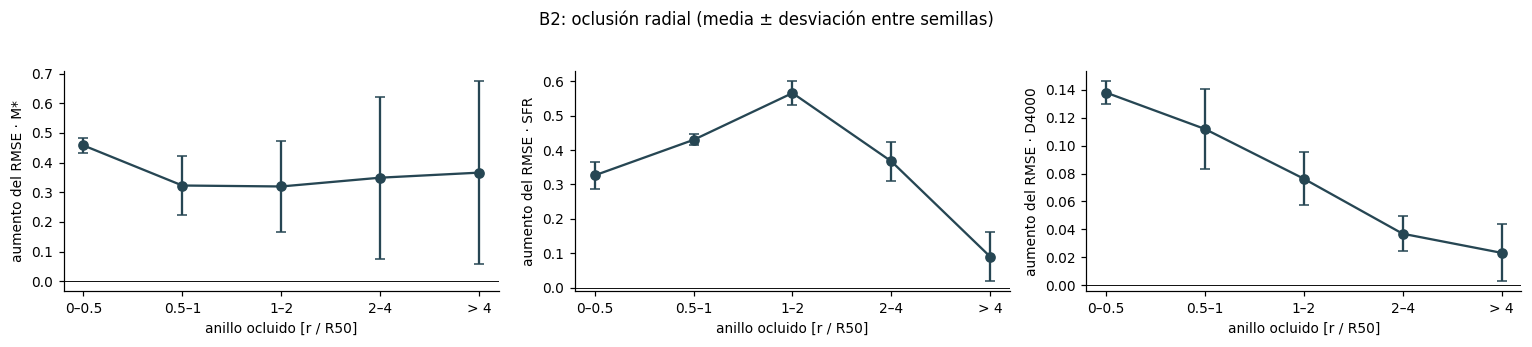

In [14]:
D_VA = datos("Validation")
r50_va = R50[VA]
ANILLOS = [(0, 0.5), (0.5, 1), (1, 2), (2, 4), (4, np.inf)]
ETQ_ANILLO = ["0–0.5", "0.5–1", "1–2", "2–4", "> 4"]
filas = []
for s, red in REDES.items():
    base = DG.predecir_con(red, D_VA)
    pruebas = [("banda", b, dict(ocluir_banda=i)) for i, b in enumerate(BANDAS_RED)]
    pruebas += [("anillo", e, dict(anillo=a, r50_px=r50_va)) for a, e in zip(ANILLOS, ETQ_ANILLO)]
    pruebas += [("plano", p, dict(permutar=p, seed=s)) for p in ("masa→SFR", "masa→D4000", "SFR→D4000")]
    for tipo, nombre, kw in pruebas:
        pm = DG.predecir_con(red, D_VA, **kw)
        for k, t in enumerate(OBJETIVOS):
            d, lo, hi = DG.delta_rmse(Y[VA, k], pm[:, k], base[:, k], n=N_BOOT)
            filas.append({"semilla": s, "tipo": tipo, "elemento": nombre, "propiedad": CORTO[t], "ΔRMSE": d, "lo": lo, "hi": hi})
IMP_B2 = pd.DataFrame(filas)
guard.write(RES / "importancia_B2.csv", lambda f: IMP_B2.to_csv(f, index=False), allow_replace=True)
resumen = IMP_B2.groupby(["tipo", "elemento", "propiedad"], sort=False)["ΔRMSE"].agg(["mean", "std"]).unstack("propiedad")
display(resumen.round(4))

def barras(tipo, titulo, etiquetas):
    fig, ax = plt.subplots(1, 3, figsize=(14, 2.9))
    for a, t in zip(ax, OBJETIVOS):
        d = IMP_B2[(IMP_B2.tipo == tipo) & (IMP_B2.propiedad == CORTO[t])]
        g = d.groupby("elemento", sort=False)["ΔRMSE"]
        principal = d[d.semilla == SEMILLA].set_index("elemento").loc[etiquetas]
        a.barh(etiquetas, g.mean().loc[etiquetas], color=COLOR["B2"], alpha=0.85)
        a.errorbar(principal["ΔRMSE"], etiquetas, xerr=[principal["ΔRMSE"] - principal.lo, principal.hi - principal["ΔRMSE"]],
                   fmt="none", ecolor="k", capsize=3)
        for s in SEMILLAS:
            v = d[d.semilla == s].set_index("elemento").loc[etiquetas, "ΔRMSE"]
            a.plot(v, etiquetas, "o", ms=3, color="#e9c46a")
        a.axvline(0, color="k", lw=0.6); a.set(xlabel=f"aumento del RMSE · {CORTO[t]}"); a.invert_yaxis()
    plt.suptitle(titulo + " (barra: media de las semillas; puntos: cada semilla; línea: IC 95 % de la semilla principal)", y=1.05)
    plt.tight_layout(); plt.show()

barras("banda", "B2: oclusión de cada banda", BANDAS_RED)

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, t in zip(ax, OBJETIVOS):
    d = IMP_B2[(IMP_B2.tipo == "anillo") & (IMP_B2.propiedad == CORTO[t])]
    g = d.groupby("elemento", sort=False)["ΔRMSE"]
    a.errorbar(range(len(ETQ_ANILLO)), g.mean().loc[ETQ_ANILLO], yerr=g.std().loc[ETQ_ANILLO].fillna(0), marker="o",
               color=COLOR["B2"], capsize=3)
    a.axhline(0, color="k", lw=0.6)
    a.set(xticks=range(len(ETQ_ANILLO)), xticklabels=ETQ_ANILLO, xlabel="anillo ocluido [r / R50]", ylabel=f"aumento del RMSE · {CORTO[t]}")
plt.suptitle("B2: oclusión radial (media ± desviación entre semillas)", y=1.03); plt.tight_layout(); plt.show()

Quitar cualquier banda aumenta mucho el error: entre 0.4 y 0.7 dex en masa, entre 0.47 y 0.63 dex en SFR y entre 0.15 y 0.32 en D4000. La red usa las tres bandas a la vez, es decir, aprendió a usar el color. Los valores absolutos están exagerados, porque una imagen sin una banda es muy diferente de las que la red vio al entrenar; lo útil es comparar el orden entre bandas. La masa depende más de las bandas r y z (0.71 y 0.67 dex) que de g (0.40). Esto concuerda con la física, porque las bandas rojas captan la luz de las estrellas viejas, que concentran la mayor parte de la masa. Sin embargo, el efecto de r cambia mucho de una semilla a otra (de 0.43 a 0.86 dex). La SFR depende más de g (0.63 dex), la banda más azul, donde domina la luz de las estrellas jóvenes. El D4000 depende sobre todo de r (0.32) y después de g (0.18); la diferencia entre ambas, el color g − r, es la que indica la edad de las estrellas.

Quitar regiones de la galaxia indica dónde está esa información, y los resultados también tienen sentido físico. En el D4000, la importancia disminuye del centro hacia afuera (de 0.14 a 0.02): la red estima la edad sobre todo con el núcleo, donde predominan las estrellas viejas. En la SFR, la región más importante está entre 1 y 2 R50 (0.57 dex), que corresponde al disco, donde se forman las estrellas; las afueras casi no importan (0.09). En la masa, el núcleo es importante y da el mismo resultado con las tres semillas (0.46 ± 0.03 dex). Las regiones exteriores también aumentan el error, pero con una variación muy grande entre semillas (0.35 ± 0.27 y 0.37 ± 0.31): dependiendo de la semilla, la red usa o no la luz de las afueras y el tamaño aparente de la galaxia. Esta forma inestable de estimar la masa se relaciona con el error que depende de la distancia, que se analiza en la sección 9.4.

### 8.3 B2: la cadena

En la cadena, la red de SFR recibe la masa que predijo la primera red, y la red de D4000 recibe la masa y la SFR. Para medir cuánto usa cada red esa información, revolvemos los valores entre galaxias: siguen siendo valores realistas, pero ya no corresponden a la galaxia de la imagen. Si el error no cambia, la red no usa esa información.

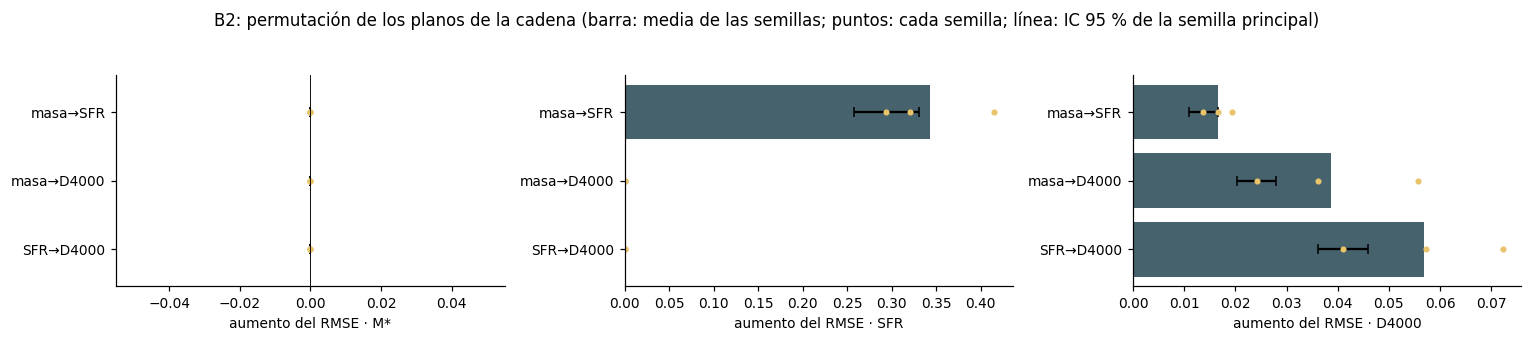

In [15]:
barras("plano", "B2: permutación de los planos de la cadena", ["masa→SFR", "masa→D4000", "SFR→D4000"])

La cadena es la decisión de diseño más particular de Katachi, y la prueba confirma que sí transmite información útil. Al revolver la masa que recibe la red de SFR, su error aumenta en 0.34 dex, de 0.61 a cerca de 0.95. La red de SFR depende mucho de la masa predicha, lo cual corresponde a la secuencia de formación estelar, en la que la SFR crece con la masa. La red de D4000 usa las dos predicciones que recibe: revolver la SFR aumenta su error en 0.057, y revolver la masa, en 0.039, aumentos grandes comparados con su error de 0.073. Cuando la masa se revuelve antes de la red de SFR, el efecto que llega hasta el D4000 es menor (0.017).

### 8.4 B2: mapas SHAP

SHAP asigna a cada píxel cuánto aumenta o disminuye la predicción, en las unidades de la propiedad, comparada con la predicción promedio de 32 galaxias de entrenamiento. Usamos `GradientExplainer` sobre la cadena completa, de modo que la contribución de un píxel incluye su efecto a través de las redes anteriores. Calculamos los mapas para 48 galaxias de validación, la mitad formadoras y la mitad apagadas, con la semilla principal.

Mostramos tres galaxias de ejemplo y el **perfil radial medio** de cada tipo de galaxia: la contribución promedio por píxel en anillos de r / R50.

Mapas SHAP calculados en 4.1 min


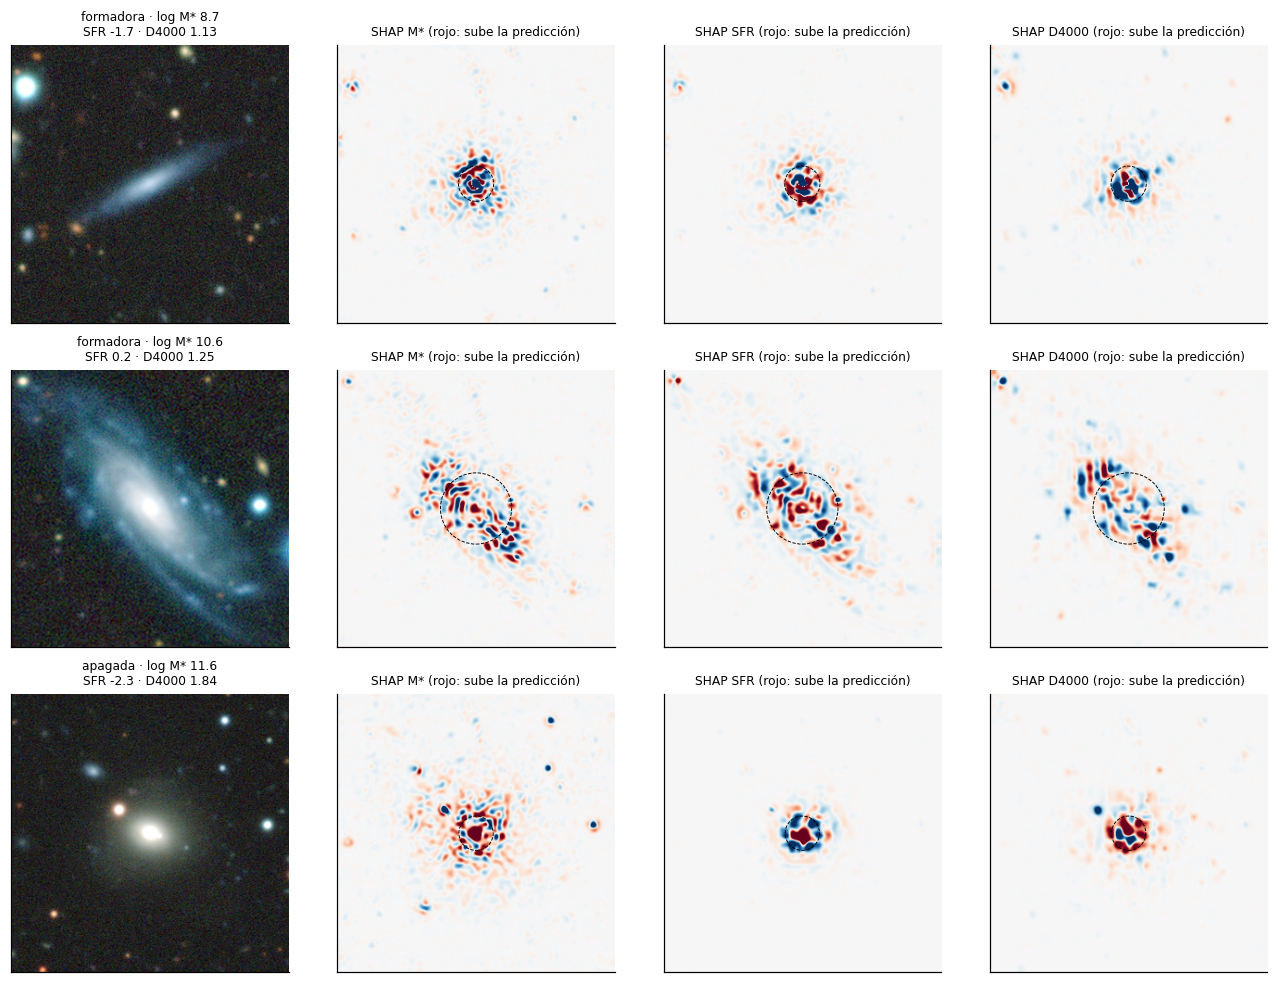

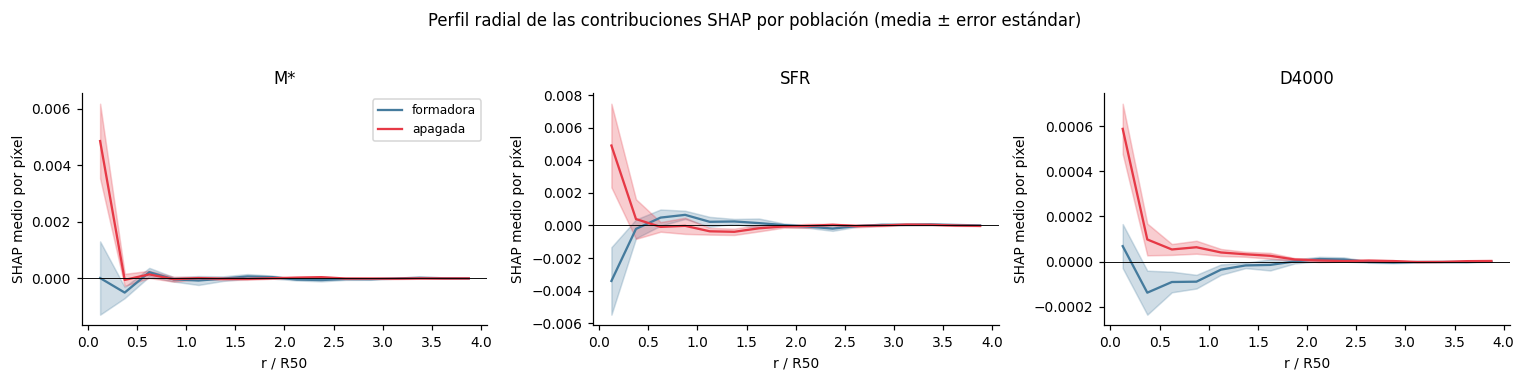

In [ ]:
red = REDES[SEMILLA]
rng = np.random.default_rng(SEMILLA)
pob_va = cohorte.poblacion.to_numpy()[VA]
n_pob = N_SHAP // 2
sel = np.concatenate([rng.choice(np.where(pob_va == p)[0], min(n_pob, int((pob_va == p).sum())), replace=False)
                      for p in ("formadora", "apagada")])
fondo = DG.entrada_red(red, torch.from_numpy(X300[rng.choice(IDX["Train"], 32, replace=False)].astype(np.float32))).float()
xs = DG.entrada_red(red, torch.from_numpy(X300[VA[sel]].astype(np.float32))).float()
t0 = time.time()
SHAP = {}
for k, t in enumerate(OBJETIVOS):
    modelo = ChainTarget(red.model, k).eval()
    SHAP[t] = SM.shap_maps(modelo, fondo, xs, batch=8, nsamples=SHAP_MUESTRAS).sum(-1)      # (N, H, W)
print(f"Mapas SHAP calculados en {(time.time() - t0) / 60:.1f} min")

bordes_u = np.arange(0, 4.01, 0.25)
lado = xs.shape[-1]
yy, xx = np.indices((lado, lado)); rr = np.hypot(yy - (lado - 1) / 2, xx - (lado - 1) / 2)
def perfil(mapa, r50):
    u = rr / r50
    return np.array([mapa[(u >= a) & (u < b)].mean() if ((u >= a) & (u < b)).any() else np.nan
                     for a, b in zip(bordes_u[:-1], bordes_u[1:])])

g = cohorte.iloc[VA[sel]]
gm, gp = g.log_mstar.to_numpy(), g.poblacion.to_numpy()
e1 = int(np.where(gp == "formadora")[0][np.argmin(gm[gp == "formadora"])])
e3 = int(np.where(gp == "apagada")[0][np.argmax(gm[gp == "apagada"])])
resto = [j for j in np.argsort(np.abs(gm - np.median(gm))) if j not in (e1, e3)]
ejemplos = [e1, int(resto[0]), e3]
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for fila_, j in enumerate(ejemplos):
    f = g.iloc[j]
    ax[fila_, 0].imshow(DG.vista_rgb(xs[j].cpu().numpy()), origin="lower")
    ax[fila_, 0].set_title(f"{f.poblacion} · log M* {f.log_mstar:.1f}\nSFR {f.log_sfr:.1f} · D4000 {f.d4000:.2f}", fontsize=8)
    for c, t in enumerate(OBJETIVOS, 1):
        m = ndimage.gaussian_filter(SHAP[t][j], 2)
        v = np.percentile(np.abs(m), 99.5)
        im = ax[fila_, c].imshow(m, origin="lower", cmap="RdBu_r", vmin=-v, vmax=v)
        ax[fila_, c].add_patch(plt.Circle(((lado - 1) / 2, (lado - 1) / 2), f.R50_px, fill=False, color="k", lw=0.6, ls="--"))
        ax[fila_, c].set_title(f"SHAP {CORTO[t]} (rojo: sube la predicción)", fontsize=8)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
uc = (bordes_u[:-1] + bordes_u[1:]) / 2
for a, t in zip(ax, OBJETIVOS):
    for p, c in (("formadora", "#457b9d"), ("apagada", "#e63946")):
        js = np.where(g.poblacion.to_numpy() == p)[0]
        prof = np.array([perfil(SHAP[t][j], g.R50_px.iloc[j]) for j in js])
        mu, se = np.nanmean(prof, 0), np.nanstd(prof, 0) / np.sqrt(np.sum(np.isfinite(prof), 0))
        a.plot(uc, mu, color=c, label=p); a.fill_between(uc, mu - se, mu + se, color=c, alpha=0.25)
    a.axhline(0, color="k", lw=0.6); a.set(xlabel="r / R50", ylabel="SHAP medio por píxel", title=CORTO[t])
ax[0].legend(fontsize=8); plt.suptitle("Perfil radial de las contribuciones SHAP por población (media ± error estándar)", y=1.03)
plt.tight_layout(); plt.show()

SHAP complementa a la oclusión: indica si cada píxel sube o baja la predicción y permite ver si la red razona de forma distinta con una galaxia formadora y con una apagada. En los mapas, las contribuciones se concentran dentro de 1 a 2 R50; los píxeles del cielo y las galaxias vecinas casi no contribuyen. En la galaxia espiral, las contribuciones a la SFR y al D4000 siguen el disco y los brazos; en la galaxia elíptica, se concentran en el núcleo. Los mapas alternan valores positivos y negativos entre píxeles vecinos, algo común en los métodos basados en gradientes, así que conviene leerlos por regiones y en promedio, no píxel por píxel.

Los perfiles radiales, que promedian las contribuciones en anillos, separan claramente a los dos tipos de galaxia. En las apagadas, los píxeles del núcleo (r < 0.25 R50) suben las tres predicciones. En la masa y el D4000 la interpretación es directa: un núcleo brillante y con estrellas viejas indica una galaxia masiva y vieja. En la SFR, el aumento probablemente proviene de la masa que recibe la red, de la que depende mucho (sección 8.3). En las formadoras, el núcleo baja la predicción de SFR y la zona entre 0.3 y 1 R50 baja la del D4000, porque un disco con estrellas jóvenes reduce la edad estimada. Más allá de 2 R50, las contribuciones son prácticamente nulas en los dos tipos de galaxia.

### 8.5 Síntesis de la importancia

| Propiedad | B1: variable que más pesa | B2: banda más importante | B2: región más importante | B2: predicciones de la cadena | Interpretación física |
|---|---|---|---|---|---|
| **Masa** | La magnitud (Mᵢ), casi por completo | r y z | El núcleo y, según la semilla, las afueras | — | La masa es la luminosidad multiplicada por el cociente masa–luminosidad. Como la imagen no da la distancia, la red la sustituye con el tamaño y el brillo aparentes |
| **SFR** | El color y después la magnitud | g, la banda más azul | El disco (1–2 R50) | Depende mucho de la masa (+0.34 dex) | Las estrellas jóvenes están en el disco y emiten luz azul; la SFR sigue la secuencia de formación estelar, que crece con la masa |
| **D4000** | Casi solo el color | r y g | El núcleo, cada vez menos hacia afuera | Usa la SFR (+0.057) y la masa (+0.039) | Las estrellas viejas del bulbo elevan el D4000, y el color g − r indica la edad |

Los cuatro métodos coinciden entre sí y con lo que se sabe de la física de las galaxias. La única señal de alerta es la masa en B2: la importancia de las afueras cambia mucho entre semillas, lo que coincide con el error que depende de la distancia (sección 9.4).

**Métodos de selección y decisión.** Los análisis anteriores corresponden a dos tipos de métodos de selección de características. En B1 usamos un método embebido: los coeficientes de la regresión indican cuánto aporta cada variable, y la regla de un error estándar decide entre la regresión lineal y el bosque. En B2, la permutación y la oclusión funcionan como un método de envoltura (*wrapper*): miden el desempeño del modelo con y sin cada entrada (una banda, una región o una predicción de la cadena) en galaxias que no se usaron para entrenar. SHAP complementa este análisis con la contribución de cada píxel. La decisión es conservar todas las entradas, porque quitar cualquier banda, la región central o una predicción de la cadena aumenta el error más allá de su intervalo de confianza. Las únicas candidatas a eliminarse serían las afueras de la galaxia (más de 4 R50) para el D4000, cuyo aporte es pequeño (0.02); las conservamos porque recortar la imagen cambiaría la entrada de la red. En B1, el color aporta poco a la masa (0.02 dex), pero se conserva porque es el término que corrige el cociente masa–luminosidad.

## 9. Sub y sobreajuste

Saber qué información usa cada modelo no indica si la aprovecha bien. Esta sección compara el error en las galaxias de entrenamiento con el error en galaxias nuevas. Un modelo **subajusta** cuando su error es alto tanto en entrenamiento como en validación: le falta capacidad o información. **Sobreajusta** cuando su error de entrenamiento es mucho menor que el de validación: memoriza particularidades de las galaxias de entrenamiento (Géron 2022, cap. 4). En este problema hay una referencia adicional: un error de entrenamiento menor que el error de las propias etiquetas indica que el modelo aprendió también su ruido.

### 9.1 Entrenamiento frente a validación

In [17]:
filas = []
for nombre, P, masc in (("B1", P_B1, cub), *((f"B2 semilla {s}", P_B2[s], None) for s in SEMILLAS)):
    for k, t in enumerate(OBJETIVOS):
        f = {"modelo": nombre, "propiedad": CORTO[t]}
        for part in ("Train", "Validation"):
            sel = IDX[part] if masc is None else IDX[part][masc[IDX[part]]]
            m = evaluar(Y[sel, k], P[sel, k], t)
            f.update({f"RMSE {part}": m["RMSE"], f"sesgo {part}": m["sesgo"], f"σ_NMAD {part}": m["sigma_NMAD"]})
        if nombre == "B1":
            f["RMSE CV"] = CV_B1[(CV_B1.propiedad == CORTO[t]) & (CV_B1.variante == ELECCION_B1[t])]["RMSE CV"].iloc[0]
        f["cociente Validation / Train"] = f["RMSE Validation"] / f["RMSE Train"]
        f["error de la etiqueta"] = RUIDO[t]
        filas.append(f)
AJUSTE = ordenar(pd.DataFrame(filas), ["propiedad", "modelo"])
display(AJUSTE.round(3))

RMSE Train  sesgo Train  σ_NMAD Train  RMSE Validation  sesgo Validation  σ_NMAD Validation  RMSE CV  cociente Validation / Train  error de la etiqueta
propiedad modelo                                                                                                                                                                  
M*        B1                    0.152       -0.000         0.138            0.153             0.001              0.134    0.152                        1.005                 0.076
          B2 semilla 42         0.183       -0.020         0.169            0.219            -0.013              0.187      NaN                        1.198                 0.076
          B2 semilla 7          0.186       -0.027         0.172            0.218            -0.021              0.195      NaN                        1.174                 0.076
          B2 semilla 2026       0.180       -0.014         0.168            0.218            -0.008              0.182      NaN                        1.212                 0.076
SFR       B1                    0.698       -0.002         0.506            0.962            -0.010              0.684    0.936                        1.377                 0.076
          B2 semilla 42         0.579       -0.042         0.403            0.611            -0.022              0.462      NaN                        1.055                 0.076
          B2 semilla 7          0.591       -0.071         0.412            0.614            -0.047              0.460      NaN                        1.039                 0.076
          B2 semilla 2026       0.599       -0.123         0.406            0.622            -0.100              0.449      NaN                        1.038                 0.076
D4000     B1                    0.090        0.000         0.073            0.123             0.004              0.107    0.120                        1.365                 0.016
          B2 semilla 42         0.073       -0.004         0.058            0.073            -0.002              0.062      NaN                        0.997                 0.016
          B2 semilla 7          0.077        0.009         0.057            0.074             0.010              0.060      NaN                        0.959                 0.016
          B2 semilla 2026       0.075       -0.002         0.057            0.073            -0.000              0.058      NaN                        0.975                 0.016

La comparación se resume en cuánto mayor es el error en validación que en entrenamiento. Además, el error de las etiquetas sirve para saber si un modelo ya está aprendiendo su ruido.

La relación color–masa no sobreajusta: su error es el mismo en entrenamiento, en validación cruzada y en validación (0.152, 0.152 y 0.153 dex). Sin embargo, ese error es el doble del de las etiquetas, lo que indica subajuste: dos variables no contienen más información. El bosque que B1 usa para la SFR y el D4000 sí sobreajusta, porque su error en validación es 37 % mayor que en entrenamiento (0.96 contra 0.70 dex en SFR, y 0.123 contra 0.090 en D4000). La validación cruzada (0.936 y 0.120) anticipó correctamente ese error, así que la estimación es confiable.

En B2, el comportamiento cambia según la propiedad. En la masa hay un sobreajuste moderado: el error en validación es entre 17 y 21 % mayor que en entrenamiento (0.218 contra 0.180–0.186 dex). En la SFR casi no hay diferencia entre los dos conjuntos (de 4 a 6 %), pero el error es ocho veces el de las etiquetas en ambos, lo que indica subajuste. En el D4000, los dos errores son prácticamente iguales. Ningún modelo llega al error de las etiquetas en entrenamiento, así que ninguno está memorizando su ruido. Entre semillas, el error total casi no cambia, pero el sesgo sí: con la semilla 2026, la SFR en validación tiene un sesgo de −0.10 dex, contra −0.02 y −0.05 de las otras dos.

### 9.2 Curvas de aprendizaje de B1

Entrenamos B1 con fracciones crecientes del conjunto de entrenamiento y medimos el error en esas mismas galaxias y en la partición de validación cruzada que se dejó fuera. Mostramos las dos variantes, la regresión lineal y el bosque, porque se comportan de forma opuesta.

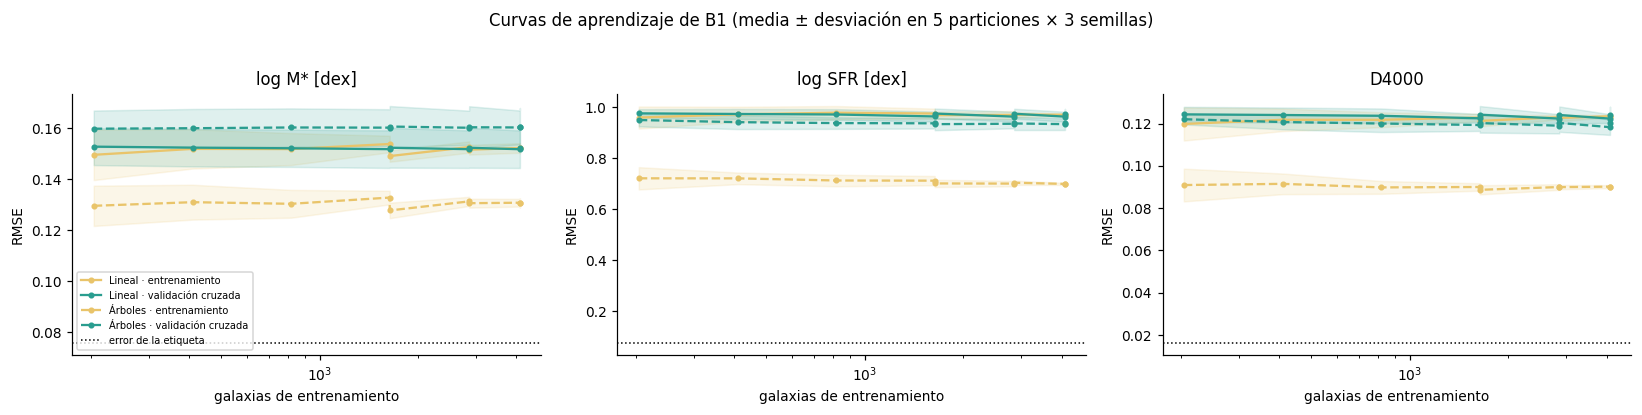

In [18]:
fracciones = np.array([0.05, 0.1, 0.2, 0.4, 0.7, 1.0])
filas = []
for k, t in enumerate(OBJETIVOS):
    for v in ("Lineal", "Árboles"):
        for s in SEMILLAS:
            for a, b in KFold(5, shuffle=True, random_state=s).split(TRc):
                orden = np.random.default_rng(s).permutation(a)
                for fr in fracciones:
                    sub = TRc[orden[:max(10, int(fr * len(orden)))]]
                    f = ajustar_b1(v, t, sub, seed=s)
                    filas.append({"propiedad": t, "variante": v, "n": len(sub),
                                  "entrenamiento": DG.metricas(Y[sub, k], f(GI[sub], MI[sub]))["RMSE"],
                                  "validación cruzada": DG.metricas(Y[TRc[b], k], f(GI[TRc[b]], MI[TRc[b]]))["RMSE"]})
CURVA = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, t in zip(ax, OBJETIVOS):
    for v, ls in (("Lineal", "-"), ("Árboles", "--")):
        d = CURVA[(CURVA.propiedad == t) & (CURVA.variante == v)].groupby("n")
        for col, c in (("entrenamiento", "#e9c46a"), ("validación cruzada", COLOR["B1"])):
            mu, sd = d[col].mean(), d[col].std()
            a.plot(mu.index, mu, ls, color=c, marker="o", ms=3, label=f"{v} · {col}")
            a.fill_between(mu.index, mu - sd, mu + sd, color=c, alpha=0.15)
    a.axhline(RUIDO[t], color="k", ls=":", lw=1, label="error de la etiqueta")
    a.set(xscale="log", xlabel="galaxias de entrenamiento", ylabel="RMSE", title=NOMBRES[t])
ax[0].legend(fontsize=6.5); plt.suptitle("Curvas de aprendizaje de B1 (media ± desviación en 5 particiones × 3 semillas)", y=1.03)
plt.tight_layout(); plt.show()

Las curvas de aprendizaje indican si tener más datos ayudaría. Las de la regresión lineal son planas y se juntan desde unas 250 galaxias: el error en entrenamiento y en validación cruzada se mantiene en 0.152 dex en masa, 0.97 dex en SFR y 0.123 en D4000. Es el comportamiento típico del subajuste: el modelo aprende todo lo que puede con muy pocos datos, y agregar galaxias no lo mejora; para mejorar se necesita más información de entrada. El bosque aleatorio, en cambio, mantiene una diferencia entre las dos curvas que no se cierra al agregar datos (0.13 contra 0.16 dex en masa, 0.70 contra 0.94 en SFR y 0.09 contra 0.12 en D4000), porque aprende parte del ruido de las galaxias de entrenamiento. Aun así, en la SFR y el D4000 su error en validación cruzada es menor que el de la regresión lineal, y por eso se eligió. Ninguno de los dos se acerca al error de las etiquetas.

### 9.3 Curvas de entrenamiento de B2

En cada época se registra el error de entrenamiento (con la aumentación activa) y el de validación de cada una de las tres redes. Entrenar la red con distintas cantidades de galaxias costaría horas de GPU, así que para B2 la evolución por época y la comparación de la sección 9.1 cumplen el papel de la curva de aprendizaje.

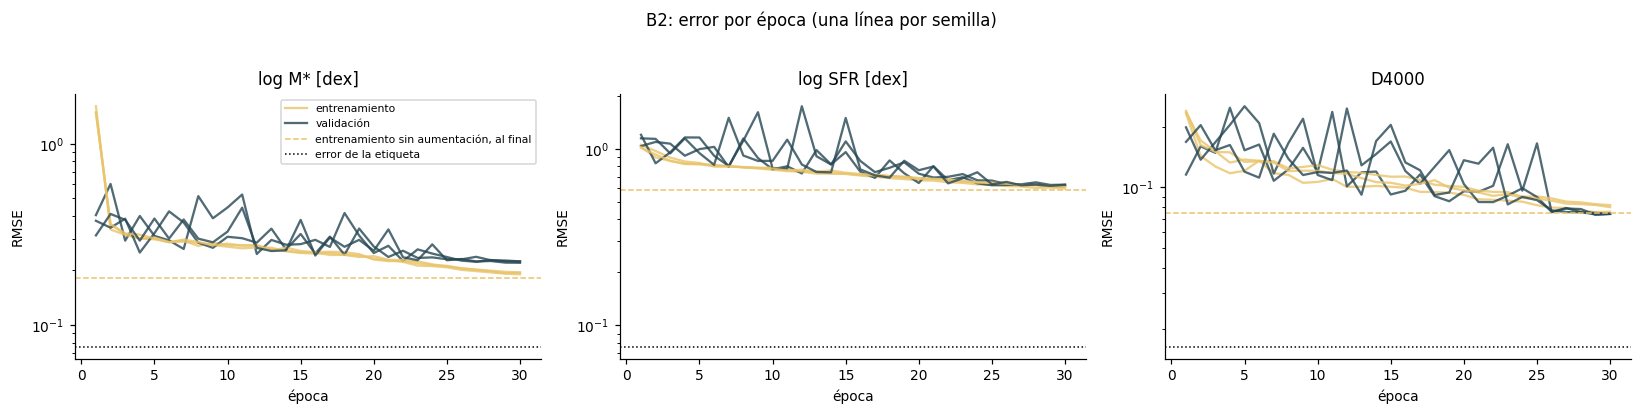

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (t, n) in zip(ax, zip(OBJETIVOS, ("mstar", "sfr", "d4000"))):
    for s in SEMILLAS:
        h = pd.read_csv(paths.run_dir(Experimento("base", MEJ, s).identificador(fcfg.crop_px)) / "history.csv")
        a.plot(h.epoch, np.sqrt(h[f"train_loss_{n}"]), color="#e9c46a", alpha=0.8, label="entrenamiento" if s == SEMILLA else None)
        a.plot(h.epoch, np.sqrt(h[f"val_loss_{n}"]), color=COLOR["B2"], alpha=0.8, label="validación" if s == SEMILLA else None)
    k = OBJETIVOS.index(t)
    a.axhline(np.mean([DG.metricas(Y[IDX["Train"], k], P_B2[s][IDX["Train"], k])["RMSE"] for s in SEMILLAS]),
              color="#e9c46a", ls="--", lw=1, label="entrenamiento sin aumentación, al final")
    a.axhline(RUIDO[t], color="k", ls=":", lw=1, label="error de la etiqueta")
    a.set(yscale="log", xlabel="época", ylabel="RMSE", title=NOMBRES[t])
ax[0].legend(fontsize=7); plt.suptitle("B2: error por época (una línea por semilla)", y=1.03); plt.tight_layout(); plt.show()

Si la red empezara a memorizar, el error de validación subiría mientras el de entrenamiento sigue bajando, y eso no ocurre. El error de entrenamiento baja de forma suave en las tres redes. El de validación varía mucho en las primeras 25 épocas, con saltos de hasta el doble, y se estabiliza al final, cuando la tasa de aprendizaje disminuye. Estas variaciones se deben a que la tasa de aprendizaje es alta al principio, no a un sobreajuste.

Para comparar de forma justa hay que usar la línea discontinua, que es el error de entrenamiento medido sin aumentación, igual que el de validación. Al final del entrenamiento, el error de validación en masa (0.22 dex) es mayor que esa línea (0.18), que es el mismo sobreajuste moderado de la sección 9.1. En la SFR y el D4000 las dos curvas terminan juntas; en la SFR, en un nivel ocho veces mayor que el error de las etiquetas. Las tres semillas siguen trayectorias muy parecidas.

### 9.4 Residuos

Los residuos (predicción − etiqueta) muestran patrones que una métrica global no ve. Graficamos la predicción frente a la etiqueta y la mediana del residuo frente al valor real y frente al redshift, junto con la franja que contiene al 68 % central de los residuos (percentiles 16 a 84). Una pendiente negativa frente al valor real indica **regresión a la media**: el modelo acerca sus predicciones al promedio, de modo que sobreestima los valores bajos y subestima los altos. Es una señal de subajuste.

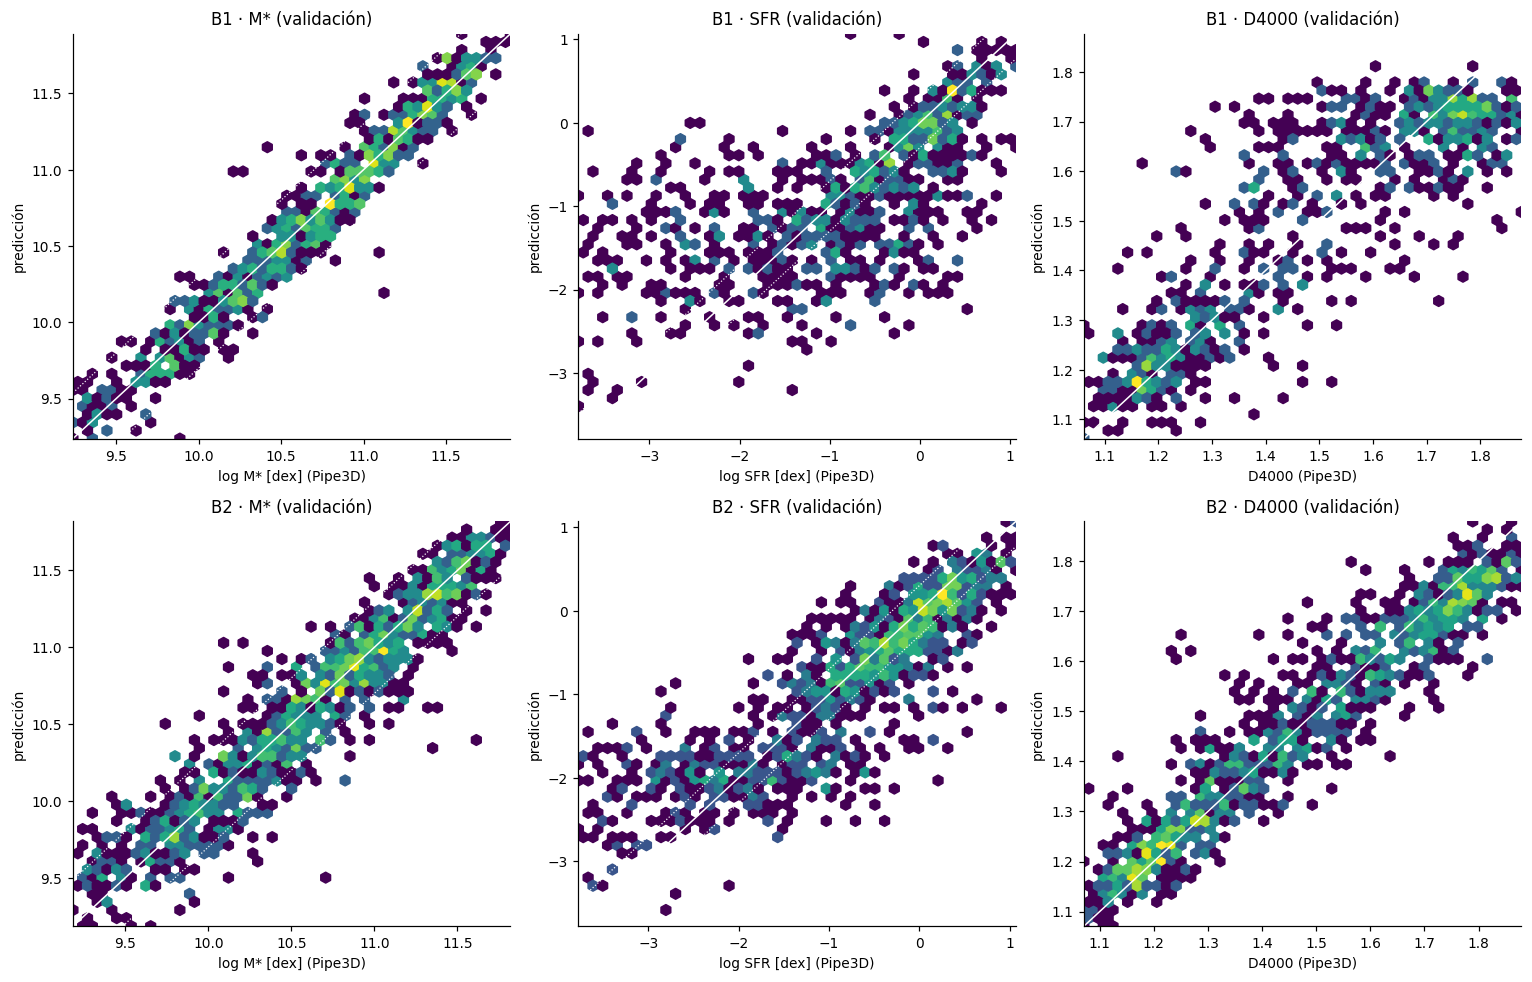

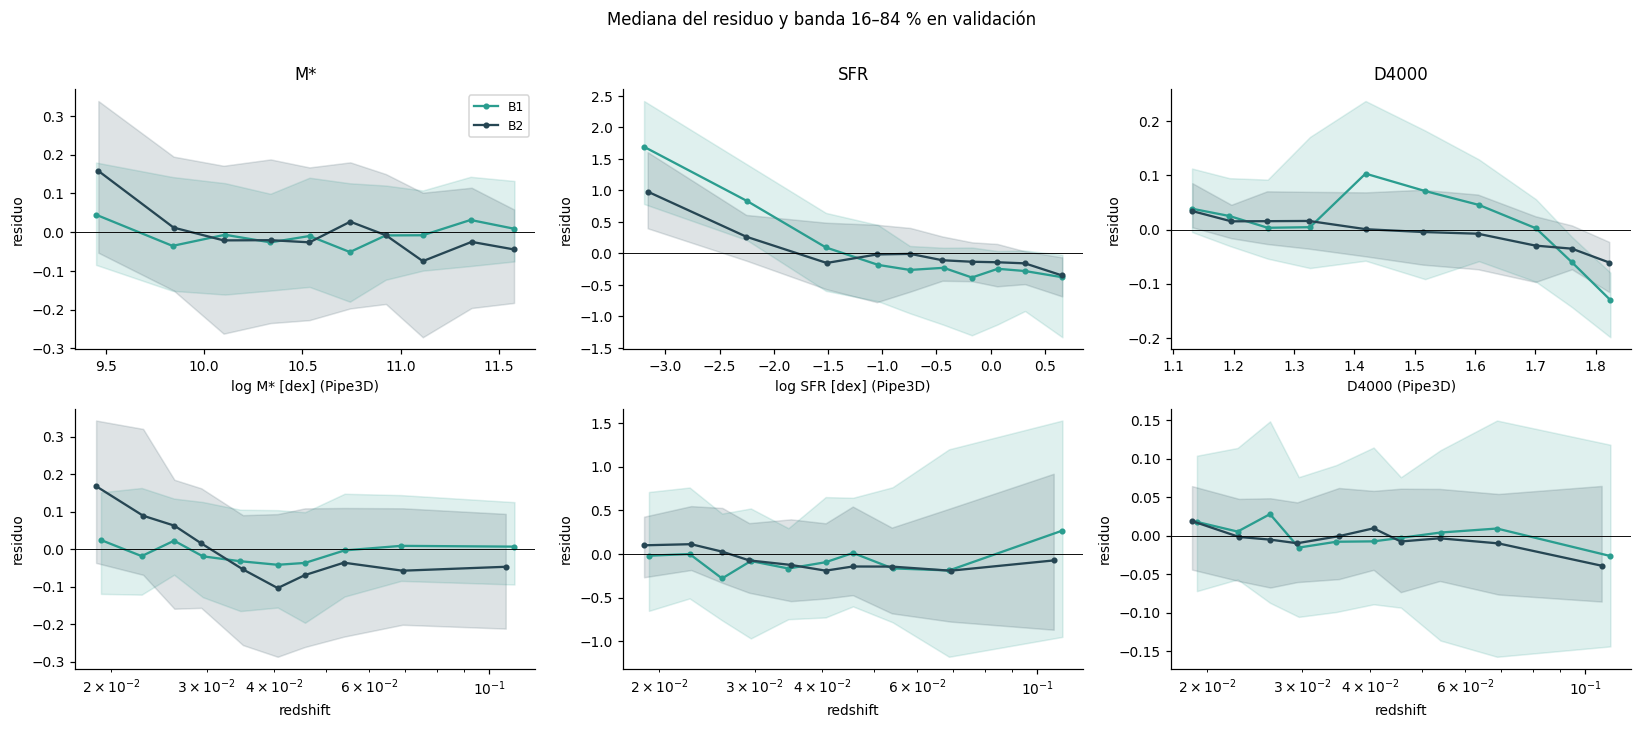

pendiente residuo–valor real  sesgo formadora  sesgo apagada
propiedad modelo                                                                       
M*        B1                                      0.003            0.026         -0.016
          B2 semilla 42                          -0.081           -0.017         -0.010
          B2 semilla 7                           -0.095           -0.022         -0.021
          B2 semilla 2026                        -0.092           -0.004         -0.012
SFR       B1                                     -0.568           -0.290          0.193
          B2 semilla 42                          -0.302           -0.182          0.118
          B2 semilla 7                           -0.300           -0.186          0.073
          B2 semilla 2026                        -0.290           -0.234          0.016
D4000     B1                                     -0.223            0.041         -0.023
          B2 semilla 42                          -0.139            0.020         -0.022
          B2 semilla 7                           -0.117            0.027         -0.005
          B2 semilla 2026                        -0.116            0.017         -0.015

In [20]:
def densidad(a, y, p, t, titulo):
    lim = np.nanpercentile(np.r_[y, p], [0.5, 99.5])
    a.hexbin(y, p, gridsize=45, cmap="viridis", mincnt=1, bins="log", extent=(*lim, *lim))
    a.plot(lim, lim, "w-", lw=1)
    if t != "d4000":
        for d in (-UMBRAL_CATASTROFICO, UMBRAL_CATASTROFICO):
            a.plot(lim, lim + d, "w:", lw=0.8)
    m = evaluar(y, p, t)
    texto = f"RMSE {m['RMSE']:.3f}\nsesgo {m['sesgo']:+.3f}\nσ_NMAD {m['sigma_NMAD']:.3f}"
    if "catastroficos" in m:
        texto += f"\n> 0.3 dex: {100 * m['catastroficos']:.1f} %"
    a.text(0.03, 0.97, texto, transform=a.transAxes, va="top", fontsize=7, color="w")
    a.set(xlim=lim, ylim=lim, xlabel=f"{NOMBRES[t]} (Pipe3D)", ylabel="predicción", title=titulo)

fig, ax = plt.subplots(2, 3, figsize=(14, 9))
sel1 = VA[cub[VA]]
for c, t in enumerate(OBJETIVOS):
    densidad(ax[0, c], Y[sel1, c], P_B1[sel1, c], t, f"B1 · {CORTO[t]} (validación)")
    densidad(ax[1, c], Y[VA, c], P_B2[SEMILLA][VA, c], t, f"B2 · {CORTO[t]} (validación)")
plt.tight_layout(); plt.show()

z = cohorte.redshift.to_numpy()
fig, ax = plt.subplots(2, 3, figsize=(15, 6.5))
for c, t in enumerate(OBJETIVOS):
    for nombre, P, sel_ in (("B1", P_B1, sel1), ("B2", P_B2[SEMILLA], VA)):
        r = P[sel_, c] - Y[sel_, c]
        for fila_, x, bordes in ((0, Y[sel_, c], np.quantile(Y[VA, c], np.linspace(0, 1, 11))),
                                 (1, z[sel_], np.quantile(z[VA], np.linspace(0, 1, 11)))):
            mm = DG.mediana_movil(x, r, bordes)
            ax[fila_, c].plot(mm["x"], mm["mediana"], "o-", ms=3, color=COLOR[nombre], label=nombre)
            ax[fila_, c].fill_between(mm["x"], mm["p16"], mm["p84"], color=COLOR[nombre], alpha=0.15)
    ax[0, c].set(xlabel=f"{NOMBRES[t]} (Pipe3D)", ylabel="residuo", title=CORTO[t])
    ax[1, c].set(xlabel="redshift", ylabel="residuo")
    if any(len(l.get_xdata()) for l in ax[1, c].lines) and np.all(z[VA] > 0):
        ax[1, c].set_xscale("log")
    for a in ax[:, c]:
        a.axhline(0, color="k", lw=0.6)
ax[0, 0].legend(fontsize=8); plt.suptitle("Mediana del residuo y banda 16–84 % en validación", y=1.01); plt.tight_layout(); plt.show()

filas = []
for nombre, P, sel_ in (("B1", P_B1, sel1), *((f"B2 semilla {s}", P_B2[s], VA) for s in SEMILLAS)):
    for c, t in enumerate(OBJETIVOS):
        r = P[sel_, c] - Y[sel_, c]
        filas.append({"modelo": nombre, "propiedad": CORTO[t], "pendiente residuo–valor real": np.polyfit(Y[sel_, c], r, 1)[0],
                      **{f"sesgo {p}": r[cohorte.poblacion.to_numpy()[sel_] == p].mean() for p in ("formadora", "apagada")}})
display(ordenar(pd.DataFrame(filas), ["propiedad", "modelo"]).round(3))

Las gráficas de predicción contra etiqueta muestran cómo se equivoca cada modelo. En la masa, B1 sigue la diagonal en todo el intervalo, con poca dispersión. En la SFR, en cambio, predice valores entre −2 y −1 para casi todas las galaxias apagadas, sin importar su valor real: con dos números no logra distinguir unas de otras. En el D4000 separa los dos grupos de galaxias, pero se equivoca con las intermedias. B2 sigue la diagonal en las tres propiedades, aunque en la SFR sus predicciones no bajan de log SFR ≈ −2.5.

La mediana del residuo confirma estos patrones y muestra una regresión a la media clara en la SFR. Para las galaxias con log SFR ≈ −3.2, B2 sobreestima en 1.0 dex y B1 en 1.7; en las de SFR más alta, ambos subestiman unos 0.35 dex. Además, B2 subestima a las formadoras (de −0.18 a −0.23 dex) y sobreestima a las apagadas (hasta +0.12), así que acerca a los dos grupos entre sí. En la masa, B2 sobreestima en 0.16 dex a las galaxias con log M\* ≈ 9.5, mientras que B1 no muestra esa tendencia. En el D4000, B1 sobreestima en 0.10 a las galaxias intermedias (entre 1.4 y 1.6), y B2 tiene una tendencia mucho menor.

El residuo contra el redshift permite ver el efecto de la distancia. En la masa, el residuo de B2 va de +0.17 dex en las galaxias más cercanas (z ≈ 0.018) a −0.10 dex en z ≈ 0.04: la red asigna más masa a las galaxias cercanas, que se ven grandes y brillantes, y menos a las lejanas. B1 no tiene este problema porque su magnitud absoluta ya incluye la distancia. En la SFR y el D4000 no hay una tendencia clara. Es la misma limitación que señalaron la comparación de la sección 7.4 y la oclusión de regiones de la sección 8.2: a la imagen le falta la distancia.

### 9.5 Diagnóstico

| Modelo y propiedad | Diagnóstico | Evidencia |
|---|---|---|
| **B1 · masa** (regresión lineal) | Subajuste por falta de información | El error es igual en entrenamiento, validación cruzada y validación (0.152–0.153 dex) y es el doble del de las etiquetas; las curvas de aprendizaje son planas y están juntas; el residuo no tiene tendencia |
| **B1 · SFR** (bosque) | Sobreajuste y falta de información | El error en validación es 37 % mayor que en entrenamiento; la diferencia no se cierra en la curva de aprendizaje; fuerte regresión a la media (pendiente −0.57) |
| **B1 · D4000** (bosque) | Sobreajuste y falta de información | El error en validación es 37 % mayor que en entrenamiento; sobreestima a las galaxias intermedias |
| **B2 · masa** | Sobreajuste moderado y sesgo por la falta de distancia | El error en validación es 17–21 % mayor que en entrenamiento; el residuo pasa de +0.17 a −0.10 dex con el redshift y es de +0.16 dex en las galaxias menos masivas |
| **B2 · SFR** | Subajuste | Los errores de entrenamiento y validación son casi iguales y ocho veces el de las etiquetas; regresión a la media (pendiente −0.30); no predice valores por debajo de log SFR ≈ −2.5 |
| **B2 · D4000** | Buen ajuste | Los errores de entrenamiento y validación son prácticamente iguales; poca regresión a la media (pendiente −0.12); el error es 4.5 veces el de las etiquetas |

**Implicación para los modelos siguientes.** Para mejorar la masa hay que darle a la red la información de distancia que la imagen no tiene; B1 muestra que, con la luminosidad, ya se llega a 0.15 dex. Para mejorar la SFR hay que enfocarse en las galaxias apagadas, para las que ningún modelo predice valores por debajo de log SFR ≈ −2.5. Más datos del mismo tipo ayudarían poco a B1. En B2, un modelo con más capacidad o con más épocas tendría que vigilar el sobreajuste en masa.

## 10. Evaluación en el conjunto de prueba

Todo lo anterior se decidió con entrenamiento y validación. Con los modelos, las variantes y los criterios fijados, registramos la elección y abrimos el conjunto de prueba **una sola vez**. El registro guarda la fecha, la versión del código y una huella digital de las predicciones de validación, para que cualquier cambio posterior quede en evidencia.

In [21]:
huella_val = hashlib.sha256(np.round(np.stack([P_B2[s][VA] for s in SEMILLAS]), 6).tobytes()).hexdigest()
registro = {"fecha_utc": datetime.now(timezone.utc).isoformat(), "commit": COMMIT, "B1": ELECCION_B1,
            "B2": [e.identificador(fcfg.crop_px) for e in EXPS], "semilla_principal": SEMILLA,
            "criterios": "criterios.json", "huella_predicciones_validacion": huella_val}
f_reg = RES / "registro_prueba.json"
if f_reg.exists():
    previo = json.loads(f_reg.read_text())
    print("La prueba se abrió por primera vez el", previo["fecha_utc"])
    if previo["huella_predicciones_validacion"] != huella_val or previo["B1"] != ELECCION_B1:
        print("AVISO: los modelos cambiaron desde la primera apertura; esta evaluación no es una prueba independiente.")
else:
    guard.write_json(f_reg, registro)
    print("Elección registrada antes de abrir la prueba:", f_reg)

TE = IDX["Test"]
D_TE = datos("Test")
for s, red in REDES.items():
    P_B2[s][TE] = red.predict(D_TE, tta=True)
del D_TE
P_KAT = cohorte[["pred_mstar", "pred_sfr", "pred_d4000"]].to_numpy(float)
KAT = np.isfinite(P_KAT).all(1)                  # galaxias con predicción publicada de Katachi
for s in SEMILLAS:
    guard.write(RES / f"predicciones_prueba_B2_seed{s}.csv",
                lambda f, s=s: pd.DataFrame({"mangaid": cohorte.mangaid.iloc[TE],
                                             **{f"pred_{t}": P_B2[s][TE, k] for k, t in enumerate(OBJETIVOS)}}).to_csv(f, index=False),
                allow_replace=True)
print("Galaxias de prueba:", len(TE), "· con predicción de Katachi:", int(np.isfinite(P_KAT[TE]).all(1).sum()),
      "· cubiertas por B1:", int(cub[TE].sum()))

Elección registrada antes de abrir la prueba: /content/drive/MyDrive/resultados_katachi_fits/avance3/registro_prueba.json
Galaxias de prueba: 918 · con predicción de Katachi: 918 · cubiertas por B1: 635


### 10.1 Métricas en prueba

N   RMSE         IC 95 % RMSE 3 semillas  sesgo  sigma_NMAD  catastroficos         R2
galaxias         propiedad modelo                                                                                          
todas            M*        Piso     918  0.628  [0.605, 0.649]                 -0.062       0.704          0.699 -9.807e-03
                           Katachi  918  0.222  [0.210, 0.234]                 -0.049       0.185          0.153  8.738e-01
                           B2       918  0.222  [0.209, 0.236]   0.223 ± 0.002 -0.018       0.179          0.155  8.734e-01
                 SFR       Piso     918  1.217  [1.169, 1.264]                 -0.088       1.129          0.858 -5.226e-03
                           Katachi  918  0.668  [0.609, 0.736]                  0.032       0.419          0.475  6.968e-01
                           B2       918  0.654  [0.605, 0.710]   0.653 ± 0.007 -0.018       0.440          0.509  7.099e-01
                 D4000     Piso     918  0.239  [0.233, 0.246]                  0.003       0.321            NaN -1.345e-04
                           Katachi  918  0.100  [0.084, 0.121]                  0.049       0.059            NaN  8.265e-01
                           B2       918  0.073  [0.068, 0.078]   0.073 ± 0.000 -0.007       0.059            NaN  9.068e-01
cubiertas por B1 M*        Piso     635  0.612  [0.586, 0.640]                 -0.092       0.678          0.682 -2.299e-02
                           B1       635  0.141  [0.131, 0.152]                  0.008       0.128          0.031  9.456e-01
                           Katachi  635  0.219  [0.204, 0.234]                 -0.042       0.185          0.146  8.694e-01
                           B2       635  0.222  [0.206, 0.240]   0.222 ± 0.003 -0.016       0.182          0.151  8.652e-01
                 SFR       Piso     635  1.267  [1.212, 1.324]                 -0.043       1.211          0.882 -1.175e-03
                           B1       635  0.919  [0.860, 0.979]                 -0.027       0.745          0.661  4.734e-01
                           Katachi  635  0.677  [0.602, 0.760]                  0.004       0.444          0.499  7.139e-01
                           B2       635  0.679  [0.621, 0.743]   0.679 ± 0.005 -0.016       0.497          0.540  7.125e-01
                 D4000     Piso     635  0.239  [0.232, 0.246]                 -0.011       0.332            NaN -1.974e-03
                           B1       635  0.117  [0.109, 0.125]                  0.002       0.104            NaN  7.597e-01
                           Katachi  635  0.092  [0.084, 0.101]                  0.049       0.062            NaN  8.522e-01
                           B2       635  0.074  [0.068, 0.080]   0.074 ± 0.000 -0.009       0.060            NaN  9.042e-01

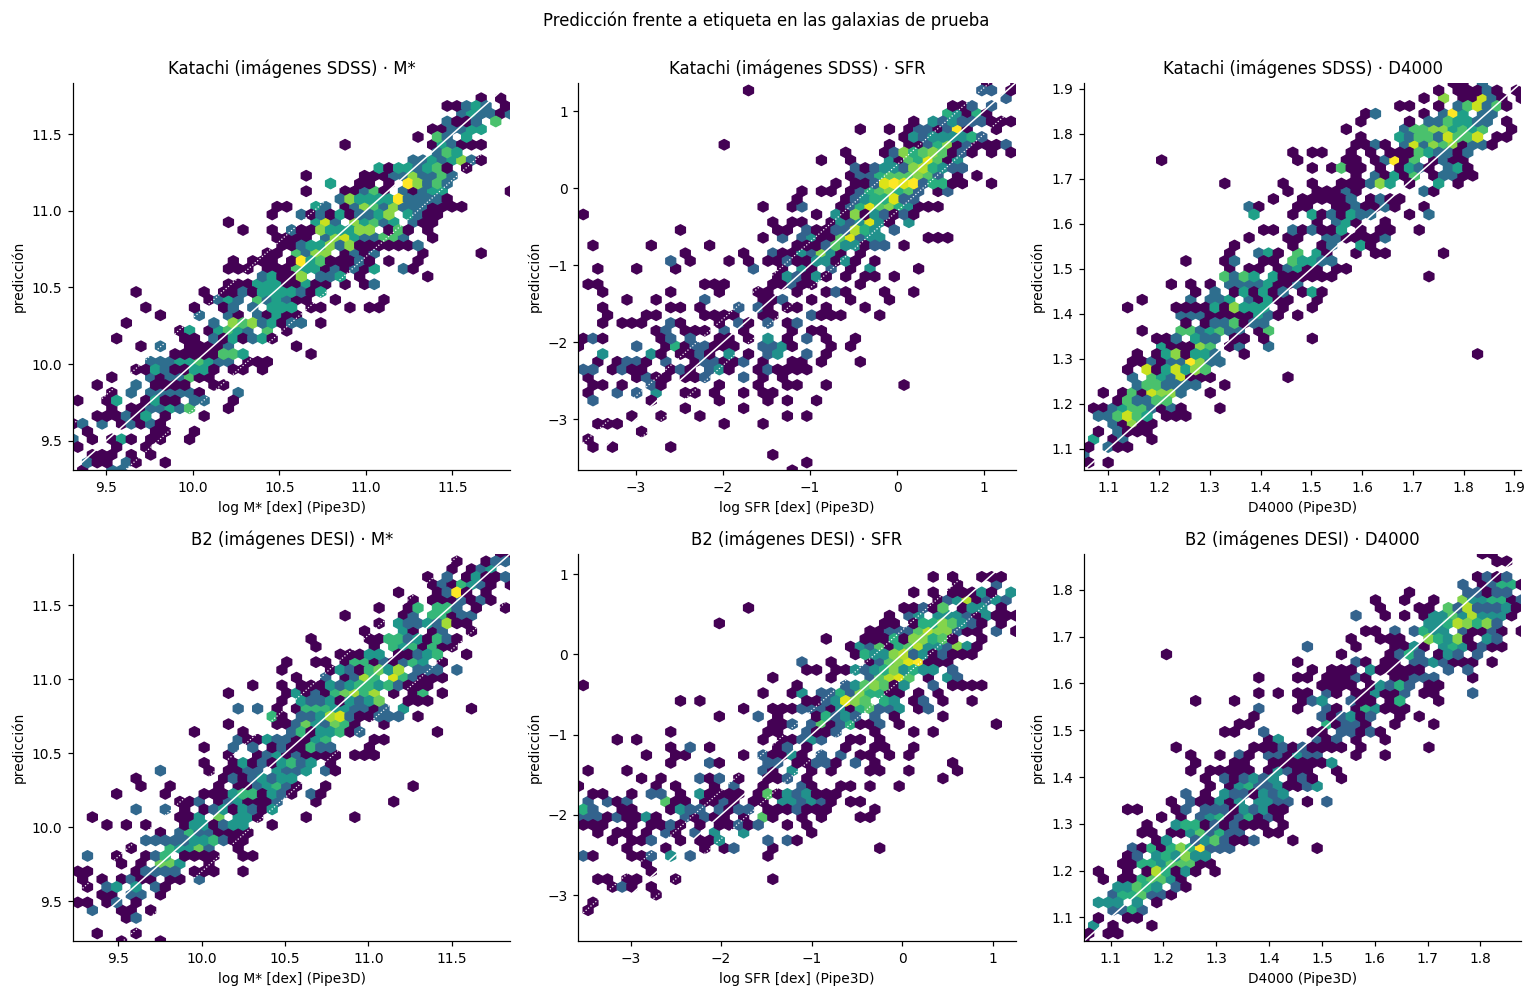

In [22]:
bloques = []
for nombre_bloque, masc, mods in (("todas", KAT, {"Piso": P_PISO, "Katachi": P_KAT, "B2": P_B2[SEMILLA]}),
                                  ("cubiertas por B1", cub & KAT, {"Piso": P_PISO, "B1": P_B1, "Katachi": P_KAT, "B2": P_B2[SEMILLA]})):
    tb = tabla(mods, TE, masc)
    sel_ = TE[masc[TE]]
    sem = {CORTO[t]: [DG.metricas(Y[sel_, k], P_B2[s][sel_, k])["RMSE"] for s in SEMILLAS] for k, t in enumerate(OBJETIVOS)}
    tb["RMSE 3 semillas"] = [f"{np.mean(sem[r.propiedad]):.3f} ± {np.std(sem[r.propiedad], ddof=1):.3f}"
                             if r.modelo == "B2" and len(SEMILLAS) > 1 else "" for r in tb.itertuples()]
    tb.insert(0, "galaxias", nombre_bloque)
    bloques.append(tb)
PRUEBA = pd.concat(bloques, ignore_index=True)
guard.write(RES / "metricas_prueba.csv", lambda f: PRUEBA.to_csv(f, index=False), allow_replace=True)
display(ordenar(PRUEBA[["galaxias", "modelo", "propiedad", "N", "RMSE", "IC 95 %", "RMSE 3 semillas", "sesgo", "sigma_NMAD",
                        "catastroficos", "R2"]], ["galaxias", "propiedad", "modelo"]))

TEK = TE[KAT[TE]]
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
for c, t in enumerate(OBJETIVOS):
    densidad(ax[0, c], Y[TEK, c], P_KAT[TEK, c], t, f"Katachi (imágenes SDSS) · {CORTO[t]}")
    densidad(ax[1, c], Y[TEK, c], P_B2[SEMILLA][TEK, c], t, f"B2 (imágenes DESI) · {CORTO[t]}")
plt.suptitle("Predicción frente a etiqueta en las galaxias de prueba", y=1.0); plt.tight_layout(); plt.show()

En las 918 galaxias de prueba, B2 tiene un error de 0.222 dex en masa, 0.654 dex en SFR y 0.073 en D4000, con muy poca variación entre semillas (0.223 ± 0.002, 0.653 ± 0.007 y 0.073 ± 0.000). Estos valores son casi iguales a los de validación (0.219, 0.611 y 0.073). El error en SFR sube un poco, pero en prueba las etiquetas también tienen más dispersión (desviación estándar de 1.22 contra 1.16). El modelo funciona igual de bien con galaxias que no se usaron en ninguna decisión.

Comparado con Katachi en las mismas galaxias y con las mismas etiquetas, el resultado cambia según la propiedad. En masa, los dos tienen el mismo error (0.222), aunque B2 tiene menos sesgo (−0.018 contra −0.049 dex). En SFR, B2 tiene un error un poco menor (0.654 contra 0.668), pero los intervalos de confianza se traslapan. En D4000, B2 es claramente mejor (0.073 contra 0.100). La diferencia no está en la dispersión, que es la misma en ambos (σ_NMAD de 0.059), sino en el sesgo: Katachi sobreestima el D4000 en 0.049 de manera sistemática, mientras que B2 casi no tiene sesgo (−0.007). En la gráfica, esto se ve como una nube de puntos de Katachi por encima de la diagonal en las galaxias viejas. En las 635 galaxias que cubre B1, la relación color–masa sigue siendo la mejor estimación de la masa (0.141 dex, contra 0.219 de Katachi y 0.222 de B2) y la peor en SFR y D4000, igual que en validación.

### 10.2 ¿Reproduce el modelo la física de la muestra?

Un modelo puede tener un RMSE bajo y aun así distorsionar las relaciones físicas que se quieren estudiar con el catálogo. Comparamos la gráfica de SFR contra masa y la distribución del D4000 de las etiquetas con las que resultan de las predicciones.

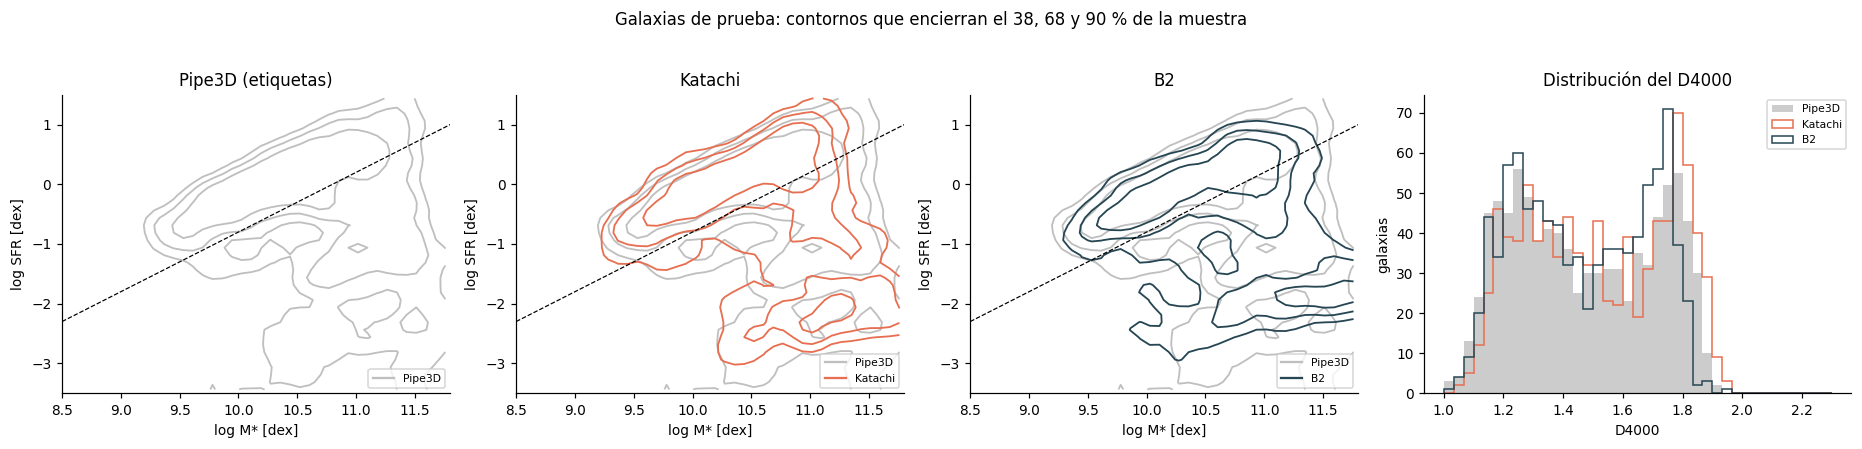

,fracción apagada (sSFR < −10.8),D4000 > 1.6,log SFR mínimo (percentil 2)
,,,
Pipe3D,0.507,0.355,-3.505
Katachi,0.489,0.418,-3.080
B2,0.538,0.347,-2.544


In [23]:
def contornos(a, x, y, color, etiqueta, rango):
    H, xe, ye = np.histogram2d(x, y, bins=40, range=rango)
    H = ndimage.gaussian_filter(H.T, 1.2)
    orden = np.sort(H.ravel())[::-1]
    acum = np.cumsum(orden) / orden.sum()
    niveles = sorted({orden[np.searchsorted(acum, q)] for q in (0.9, 0.68, 0.38)})
    a.contour((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2, H, levels=niveles, colors=color, linewidths=1.2)
    a.plot([], [], color=color, label=etiqueta)

rango = [[8.5, 11.8], [-3.5, 1.5]]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for a, (nombre, P, c) in zip(ax[:3], (("Pipe3D (etiquetas)", np.c_[Y], "k"), ("Katachi", P_KAT, COLOR["Katachi"]),
                                      ("B2", P_B2[SEMILLA], COLOR["B2"]))):
    contornos(a, Y[TEK, 0], Y[TEK, 1], "0.75", "Pipe3D", rango)
    if nombre != "Pipe3D (etiquetas)":
        contornos(a, P[TEK, 0], P[TEK, 1], c, nombre, rango)
    a.plot(np.array(rango[0]), np.array(rango[0]) + CORTE_SSFR, "k--", lw=0.8)
    a.set(xlim=rango[0], ylim=rango[1], xlabel=NOMBRES["log_mstar"], ylabel=NOMBRES["log_sfr"], title=nombre); a.legend(fontsize=7, loc="lower right")
b = np.linspace(1.0, 2.3, 40)
ax[3].hist(Y[TEK, 2], b, color="0.8", label="Pipe3D")
ax[3].hist(P_KAT[TEK, 2], b, histtype="step", lw=1.6, color=COLOR["Katachi"], label="Katachi")
ax[3].hist(P_B2[SEMILLA][TEK, 2], b, histtype="step", lw=1.6, color=COLOR["B2"], label="B2")
ax[3].set(xlabel="D4000", ylabel="galaxias", title="Distribución del D4000"); ax[3].legend(fontsize=7)
plt.suptitle("Galaxias de prueba: contornos que encierran el 38, 68 y 90 % de la muestra", y=1.03); plt.tight_layout(); plt.show()

filas = []
for nombre, P in (("Pipe3D", np.c_[Y]), ("Katachi", P_KAT), ("B2", P_B2[SEMILLA])):
    ss = P[TEK, 1] - P[TEK, 0]
    filas.append({"": nombre, "fracción apagada (sSFR < −10.8)": np.mean(ss < CORTE_SSFR),
                  "D4000 > 1.6": np.mean(P[TEK, 2] > 1.6), "log SFR mínimo (percentil 2)": np.percentile(P[TEK, 1], 2)})
display(pd.DataFrame(filas).set_index("").round(3))

B2 reproduce bien la secuencia de galaxias formadoras: su posición, su pendiente y su ancho coinciden con las de las etiquetas. Las galaxias apagadas aparecen en el lugar correcto, pero su SFR queda comprimida hacia valores más altos: el 2 % de las predicciones más bajas llega a log SFR = −2.54, mientras que en las etiquetas llega a −3.51. Katachi llega más abajo (−3.08), aunque su grupo de galaxias apagadas también es más estrecho que el real.

Las proporciones de cada tipo de galaxia se mantienen. Según B2, el 54 % de las galaxias están apagadas, contra el 51 % real (Katachi: 49 %). En el D4000, B2 reproduce los dos grupos y la fracción de galaxias viejas (D4000 > 1.6: 34.7 % contra 35.5 % real), mientras que Katachi la sobreestima (41.8 %) porque desplaza hacia arriba el pico de las galaxias viejas. Para estudios que separan a los dos tipos de galaxia, B2 es una base adecuada; para estudiar la SFR de las galaxias apagadas, todavía no lo es. Falta comprobar si las diferencias con Katachi son mayores que la incertidumbre, que es lo que hace la siguiente sección.

### 10.3 Comparación con Katachi galaxia por galaxia y por grupos

N  ΔRMSE (B2 − Katachi) veredicto para B2           IC 95 %
grupo      propiedad semilla                                                               
todas      M*        42       918             3.000e-04       equivalente  [-0.014, +0.014]
                     7        918             2.800e-03       equivalente  [-0.010, +0.016]
                     2026     918            -1.000e-03       equivalente  [-0.015, +0.013]
           SFR       42       918            -1.460e-02    no concluyente  [-0.056, +0.028]
                     7        918            -2.340e-02    no concluyente  [-0.064, +0.019]
                     2026     918            -9.400e-03    no concluyente  [-0.051, +0.033]
           D4000     42       918            -2.660e-02             mejor  [-0.048, -0.011]
                     7        918            -2.580e-02             mejor  [-0.047, -0.011]
                     2026     918            -2.650e-02             mejor  [-0.048, -0.011]
formadoras M*        42       453             1.780e-02    no concluyente  [-0.004, +0.039]
                     7        453             1.860e-02    no concluyente  [-0.002, +0.037]
                     2026     453             1.520e-02    no concluyente  [-0.006, +0.035]
           SFR       42       453             1.052e-01              peor  [+0.035, +0.179]
                     7        453             1.057e-01              peor  [+0.034, +0.177]
                     2026     453             1.329e-01              peor  [+0.061, +0.208]
           D4000     42       453            -2.000e-02             mejor  [-0.027, -0.013]
                     7        453            -1.340e-02             mejor  [-0.021, -0.006]
                     2026     453            -1.730e-02             mejor  [-0.025, -0.010]
apagadas   M*        42       465            -1.820e-02             mejor  [-0.034, -0.003]
                     7        465            -1.360e-02    no concluyente  [-0.030, +0.003]
                     2026     465            -1.810e-02             mejor  [-0.034, -0.002]
           SFR       42       465            -7.910e-02             mejor  [-0.138, -0.021]
                     7        465            -9.400e-02             mejor  [-0.150, -0.039]
                     2026     465            -8.810e-02             mejor  [-0.144, -0.031]
           D4000     42       465            -3.190e-02             mejor  [-0.068, -0.006]
                     7        465            -3.590e-02             mejor  [-0.070, -0.010]
                     2026     465            -3.380e-02             mejor  [-0.069, -0.008]

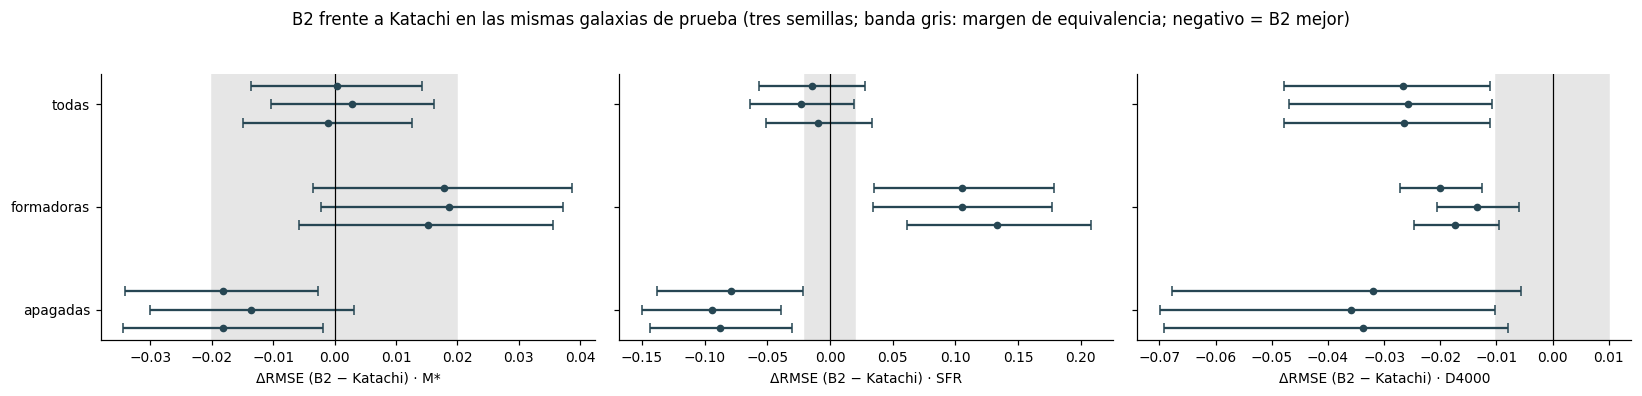

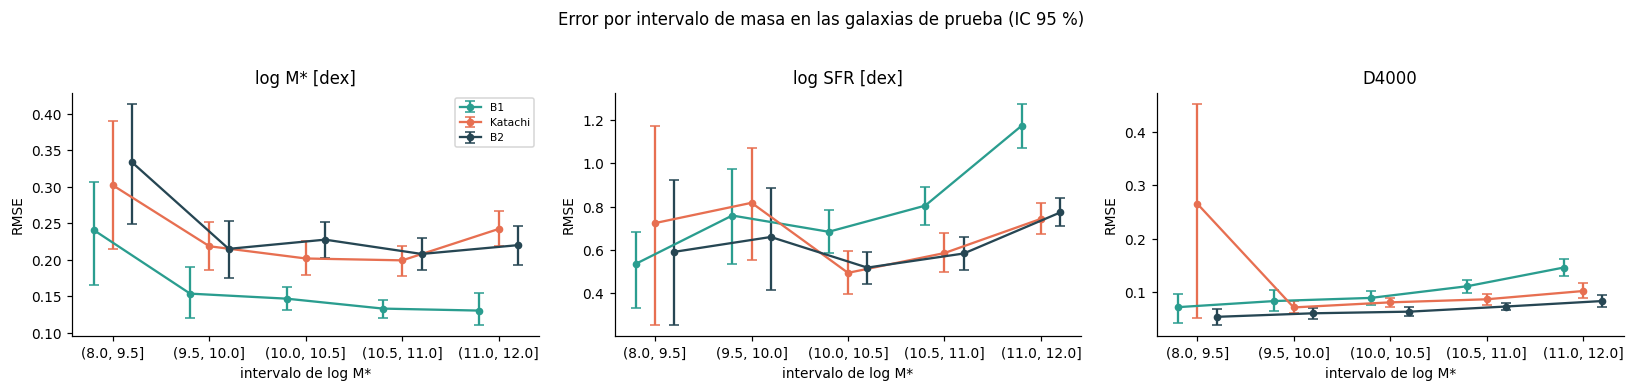

In [24]:
pobl = cohorte.poblacion.to_numpy()
filas = []
for grupo, msk in (("todas", np.ones(len(cohorte), bool)), ("formadoras", pobl == "formadora"), ("apagadas", pobl == "apagada")):
    sel_ = TE[msk[TE] & KAT[TE]]
    for k, t in enumerate(OBJETIVOS):
        for s in SEMILLAS:
            d, lo, hi = DG.delta_rmse(Y[sel_, k], P_B2[s][sel_, k], P_KAT[sel_, k], n=N_BOOT)
            filas.append({"grupo": grupo, "propiedad": CORTO[t], "semilla": s, "N": len(sel_), "ΔRMSE (B2 − Katachi)": d,
                          "lo": lo, "hi": hi, "veredicto para B2": veredicto(lo, hi, MARGEN[t])})
PAR = pd.DataFrame(filas)
display(PAR.assign(**{"IC 95 %": [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(PAR.lo, PAR.hi)]})
           .drop(columns=["lo", "hi"]).set_index(["grupo", "propiedad", "semilla"]).round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
grupos = ["todas", "formadoras", "apagadas"]
for a, t in zip(ax, OBJETIVOS):
    for gi_, gr in enumerate(grupos):
        d = PAR[(PAR.grupo == gr) & (PAR.propiedad == CORTO[t])]
        for j, (_, r) in enumerate(d.iterrows()):
            yv, v = gi_ + (j - 1) * 0.18, r["ΔRMSE (B2 − Katachi)"]
            a.errorbar(v, yv, xerr=[[v - r.lo], [r.hi - v]], fmt="o", color=COLOR["B2"], capsize=3, ms=4)
    a.axvline(0, color="k", lw=0.8); a.axvspan(-MARGEN[t], MARGEN[t], color="0.9", zorder=0)
    a.set(xlabel=f"ΔRMSE (B2 − Katachi) · {CORTO[t]}", yticks=range(3), yticklabels=grupos)
ax[0].invert_yaxis()
plt.suptitle("B2 frente a Katachi en las mismas galaxias de prueba (tres semillas; banda gris: margen de equivalencia; negativo = B2 mejor)", y=1.04)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
bm = pd.cut(cohorte.log_mstar, BORDES_M).astype(str).to_numpy()
cats = [str(c) for c in pd.cut(cohorte.log_mstar, BORDES_M).cat.categories]
for a, (k, t) in zip(ax, enumerate(OBJETIVOS)):
    for j, (nombre, P, msk) in enumerate((("B1", P_B1, cub), ("Katachi", P_KAT, None), ("B2", P_B2[SEMILLA], None))):
        xs_, ys_, es_ = [], [], []
        for i, cat in enumerate(cats):
            sel_ = TE[(bm[TE] == cat) & KAT[TE] & (np.ones(len(cohorte), bool) if msk is None else msk)[TE]]
            sel_ = sel_[np.isfinite(P[sel_, k])]
            if len(sel_) >= 10:
                lo, hi = DG.rmse_ic(Y[sel_, k], P[sel_, k], n=N_BOOT)
                v = DG.metricas(Y[sel_, k], P[sel_, k])["RMSE"]
                xs_.append(i + (j - 1) * 0.2); ys_.append(v); es_.append([v - lo, hi - v])
        a.errorbar(xs_, ys_, yerr=np.array(es_).T, fmt="o-", color=COLOR[nombre], capsize=3, label=nombre, ms=4)
    a.set(xticks=range(len(cats)), xticklabels=cats, xlabel="intervalo de log M*", ylabel="RMSE", title=NOMBRES[t])
ax[0].legend(fontsize=7); plt.suptitle("Error por intervalo de masa en las galaxias de prueba (IC 95 %)", y=1.03); plt.tight_layout(); plt.show()

Comparar los errores galaxia por galaxia elimina las diferencias entre muestras, y separar por tipo de galaxia y por masa muestra dónde gana o pierde cada modelo. El resultado cambia según la propiedad y es el mismo con las tres semillas.

En masa, B2 y Katachi son equivalentes: la diferencia está entre −0.001 y +0.003 dex, y todo el intervalo de confianza queda dentro del margen de ±0.02 dex. Por tipo de galaxia, B2 es un poco peor en las formadoras (+0.015 a +0.019 dex, sin una conclusión firme) y mejor en las apagadas (−0.014 a −0.018 dex). En SFR no hay una conclusión firme: la diferencia favorece a B2 (de −0.009 a −0.023 dex), pero el intervalo sale del margen. Esto se debe a que combina dos efectos opuestos: B2 es peor en las formadoras (+0.11 a +0.13 dex) y mejor en las apagadas (−0.08 a −0.09 dex). En D4000, B2 es mejor en el total (−0.026, con todo el intervalo por debajo de 0) y también en los dos tipos de galaxia.

Por intervalo de masa, B1 da la mejor estimación de la masa en todos los intervalos por encima de log M\* = 9.5 (0.13–0.15 dex, contra 0.20–0.24 de los modelos con imagen). En las galaxias menos masivas, B2 tiene su peor desempeño (0.33 dex), aunque con un intervalo amplio porque hay pocas. En SFR, B2 y Katachi son parecidos en todos los intervalos, y B1 es mucho peor en las galaxias más masivas (1.17 dex). En D4000, B2 tiene el menor error en todos los intervalos.

### 10.4 ¿Se alcanza el desempeño mínimo?

In [25]:
filas = []
for k, t in enumerate(OBJETIVOS):
    for nombre, P, msk in (("B1", P_B1, cub), ("B2", P_B2[SEMILLA], None)):
        sel_ = TE if msk is None else TE[msk[TE]]
        lo, hi = DG.rmse_ic(Y[sel_, k], P[sel_, k], n=N_BOOT)
        piso = DG.metricas(Y[sel_, k], P_PISO[sel_, k])["RMSE"]
        filas.append({"criterio": "Viabilidad", "modelo": nombre, "propiedad": CORTO[t],
                      "valor": f"IC [{lo:.3f}, {hi:.3f}] frente al piso {piso:.3f}", "cumple": hi < piso})
    d = PAR[(PAR.grupo == "todas") & (PAR.propiedad == CORTO[t])]
    filas.append({"criterio": "Desempeño mínimo (no peor que Katachi)", "modelo": "B2", "propiedad": CORTO[t],
                  "valor": "límite superior de ΔRMSE: " + ", ".join(f"{h:+.3f}" for h in d.hi) + f" (margen {MARGEN[t]})",
                  "cumple": bool((d.hi < MARGEN[t]).all())})
rm = [DG.metricas(Y[TE, 0], P_B2[s][TE, 0])["RMSE"] for s in SEMILLAS]
filas.append({"criterio": "Deseable en masa", "modelo": "B2", "propiedad": "M*",
              "valor": f"RMSE {np.mean(rm):.3f} frente a {MASA_DESEABLE}", "cumple": np.mean(rm) <= MASA_DESEABLE})
VERIF = pd.DataFrame(filas)
display(VERIF.style.map(lambda v: "background-color: #d8f3dc" if v is True else ("background-color: #ffd6d6" if v is False else ""),
                        subset=["cumple"]))

,criterio,modelo,propiedad,valor,cumple
1,Viabilidad,B1,M*,"IC [0.131, 0.152] frente al piso 0.612",Sí
2,Viabilidad,B2,M*,"IC [0.209, 0.236] frente al piso 0.628",Sí
3,Desempeño mínimo (no peor que Katachi),B2,M*,"límite superior de ΔRMSE: +0.014, +0.016, +0.013 (margen 0.02)",Sí
4,Viabilidad,B1,SFR,"IC [0.860, 0.979] frente al piso 1.267",Sí
5,Viabilidad,B2,SFR,"IC [0.605, 0.710] frente al piso 1.217",Sí
6,Desempeño mínimo (no peor que Katachi),B2,SFR,"límite superior de ΔRMSE: +0.028, +0.019, +0.033 (margen 0.02)",No
7,Viabilidad,B1,D4000,"IC [0.109, 0.125] frente al piso 0.239",Sí
8,Viabilidad,B2,D4000,"IC [0.068, 0.078] frente al piso 0.239",Sí
9,Desempeño mínimo (no peor que Katachi),B2,D4000,"límite superior de ΔRMSE: -0.011, -0.011, -0.011 (margen 0.01)",Sí
10,Deseable en masa,B2,M*,RMSE 0.223 frente a 0.15,No


Con estos resultados podemos verificar cada criterio de la sección 6. La viabilidad se cumple en todos los casos: B1 y B2 tienen errores muy por debajo del modelo que predice el promedio en las tres propiedades. Incluso en el peor caso, B1 en SFR, el límite superior es de 0.98 dex, lejos de los 1.27 dex del promedio. Es decir, el problema se puede abordar con métodos simples.

El desempeño mínimo se cumple en masa y en D4000, pero no en SFR. En masa, la diferencia con Katachi tiene un límite superior de +0.013 a +0.016 dex, dentro del margen de 0.02 con las tres semillas. En D4000, B2 es mejor que Katachi (límite superior de −0.011). En SFR, el valor estimado favorece a B2, pero el límite superior (+0.019, +0.028 y +0.033) sale del margen con dos de las tres semillas. Por lo tanto, no podemos asegurar que B2 no sea peor que Katachi por más de 0.02 dex. Hay dos razones: la SFR tiene tanta dispersión que 918 galaxias no alcanzan para un intervalo tan estrecho, y B2 pierde en las galaxias formadoras lo que gana en las apagadas.

El desempeño deseable en masa tampoco se cumple: B2 tiene 0.223 dex, contra la meta de 0.15. La relación color–masa sí lo cumple en las galaxias que cubre (0.141 dex), lo que confirma que la limitación de B2 en masa es la falta de información sobre la distancia. En resumen, B2 iguala a Katachi en masa, lo supera en D4000 y queda a la par en SFR, sin poder demostrar que no es peor con el margen establecido. Es un baseline sólido para el proyecto, con sus limitaciones identificadas, y la siguiente sección lo convierte en la referencia para los modelos que vienen.

### 10.5 Marco de referencia para los modelos siguientes

La tabla fija lo que un modelo nuevo deberá demostrar para considerarse una mejora sobre el baseline. Se guarda en `marco_referencia.csv`.

**Regla de decisión.** Un modelo nuevo mejora al baseline en una propiedad si, en las galaxias de validación y con tres semillas, todo el intervalo de confianza del 95 % de la diferencia RMSE(nuevo) − RMSE(B2) queda por debajo de 0, y ninguna otra propiedad empeora. Si el intervalo queda dentro del margen, los dos modelos se consideran equivalentes. El conjunto de prueba solo se usa para confirmar al modelo final, una vez.

In [26]:
filas = []
for k, t in enumerate(OBJETIVOS):
    rv = [DG.metricas(Y[VA, k], P_B2[s][VA, k])["RMSE"] for s in SEMILLAS]
    rt = [DG.metricas(Y[TE, k], P_B2[s][TE, k])["RMSE"] for s in SEMILLAS]
    pobs = {p: np.mean([DG.metricas(Y[VA[pobl[VA] == p], k], P_B2[s][VA[pobl[VA] == p], k])["RMSE"] for s in SEMILLAS])
            for p in ("formadora", "apagada")}
    filas.append({"propiedad": CORTO[t], "B2 validación (media 3 semillas)": np.mean(rv), "B2 prueba (media 3 semillas)": np.mean(rt),
                  "B2 validación, formadoras": pobs["formadora"], "B2 validación, apagadas": pobs["apagada"],
                  "variación entre semillas (validación)": np.std(rv, ddof=1) if len(rv) > 1 else np.nan,
                  "margen de equivalencia": MARGEN[t], "piso": SIGMA[t], "error de la etiqueta": RUIDO[t]})
MARCO = pd.DataFrame(filas).set_index("propiedad")
guard.write(RES / "marco_referencia.csv", lambda f: MARCO.to_csv(f), allow_replace=True)
display(MARCO.round(3))

,B2 validación (media 3 semillas),B2 prueba (media 3 semillas),"B2 validación, formadoras","B2 validación, apagadas",variación entre semillas (validación),margen de equivalencia,piso,error de la etiqueta
propiedad,,,,,,,,
M*,0.218,0.223,0.236,0.202,0.001,0.02,0.656,0.076
SFR,0.615,0.653,0.421,0.744,0.006,0.02,1.164,0.076
D4000,0.073,0.073,0.060,0.083,0.000,0.01,0.236,0.016


Los modelos siguientes deberán superar estos valores: 0.218 dex en masa, 0.615 dex en SFR y 0.073 en D4000, en validación y como promedio de tres semillas. La variación entre semillas es muy pequeña (0.001, 0.006 y menos de 0.001), así que una mejora de 0.02 dex en masa y SFR, o de 0.01 en D4000, se podrá detectar. Por tipo de galaxia, donde hay más espacio para mejorar es en la SFR de las galaxias apagadas (0.744 dex, contra 0.421 en las formadoras) y en la masa de las formadoras (0.236 contra 0.202 dex).

## 11. Conclusiones de la fase de ingeniería del modelo (CRISP-ML(Q))

En CRISP-ML(Q), la fase de *Model Engineering* exige definir las métricas de calidad del modelo, documentar los riesgos que pueden comprometer su desempeño y aplicar métodos de aseguramiento de calidad, entre ellos la validación del desempeño medio con distintas semillas y el registro de los metadatos del entrenamiento (Studer et al. 2021).

| Tarea | Requisito | Riesgo | Control de calidad aplicado |
|---|---|---|---|
| **Definir la métrica** | Medida alineada con el uso científico del catálogo | Una métrica global que oculte errores en grupos pequeños de galaxias | RMSE en dex con su lectura como factor; sesgo, σ_NMAD y errores catastróficos; métricas por tipo de galaxia y por masa (secciones 5 y 10.3) |
| **Fijar el desempeño mínimo** | Umbral con referencia externa | Elegir el umbral después de ver los resultados | Referencias históricas y criterios registrados antes de evaluar (sección 6) |
| **Seleccionar el modelo** | Algoritmo apropiado para el tipo de dato | Usar un modelo complejo sin saber cuánto aporta | Comparación de modelos de complejidad creciente; regla de un error estándar en B1 (sección 7) |
| **Entrenar** | Resultados reproducibles | Depender de una semilla favorable | Tres semillas; código versionado; configuración y pesos guardados por corrida (sección 7.3) |
| **Interpretar** | Saber qué información usa cada modelo | Un modelo que acierta por razones equivocadas | Permutación, oclusión de bandas y regiones, permutación de las predicciones de la cadena y SHAP (sección 8) |
| **Diagnosticar el ajuste** | Detectar sub y sobreajuste | Memorizar el ruido de las etiquetas o no captar la señal | Entrenamiento frente a validación, curvas de aprendizaje y de entrenamiento, residuos (sección 9) |
| **Evaluar** | Estimación honesta del desempeño | Ajustar decisiones al conjunto de prueba | Elección registrada antes de abrir la prueba; prueba abierta una sola vez; comparación con Katachi galaxia por galaxia (sección 10) |

**Respuestas a las preguntas del avance.**

1. **¿Qué algoritmo se puede utilizar como baseline?** Como el proyecto parte de imágenes, el baseline es la cadena de tres ResNet50 de Katachi, preentrenadas con ImageNet. Es el método publicado para estas mismas etiquetas, es adecuado para datos no estructurados y para una muestra de siete mil galaxias, y se puede interpretar con oclusión y SHAP. Como referencia simple sirve la relación color–masa con el término −0.4 Mᵢ fijo y, para la SFR y el D4000, un bosque aleatorio con el color y la magnitud, elegido por validación cruzada.
2. **¿Se puede determinar la importancia de las características?** Sí. En B1, la magnitud explica casi toda la masa, y el color es la variable más importante para la SFR y el D4000. En B2, la red usa las tres bandas, sobre todo g para la SFR y r para el D4000; usa el disco para estimar la SFR y el núcleo para el D4000, y la red de SFR depende mucho de la masa que le pasa la primera red. Ninguna entrada sobra.
3. **¿El modelo está sub o sobreajustando?** B2 sobreajusta un poco en masa (su error en validación es 17–21 % mayor que en entrenamiento), subajusta en SFR (los dos errores son iguales y ocho veces el de las etiquetas) y tiene un buen ajuste en D4000. B1 subajusta en masa por falta de información, y su bosque sobreajusta en SFR y D4000. Ningún modelo aprende el ruido de las etiquetas.
4. **¿Cuál es la métrica adecuada?** El RMSE en dex: se interpreta como un factor multiplicativo, castiga los errores grandes que confunden a los dos tipos de galaxia y permite comparar con la literatura. Lo complementamos con el sesgo y la dispersión típica, y lo reportamos por tipo de galaxia y por intervalo de masa, porque el valor global oculta que B2 es mejor que Katachi en las galaxias apagadas y peor en las formadoras.
5. **¿Cuál debería ser el desempeño mínimo?** El de Katachi publicado: 0.222 dex en masa, 0.668 dex en SFR y 0.100 en D4000. B2 lo alcanza en masa, lo supera en D4000 y queda a la par en SFR, aunque sin poder demostrar que no es peor con el margen de 0.02 dex. Los modelos siguientes deberán superar a B2 en validación con tres semillas: 0.218, 0.615 y 0.073.

**Lo que este avance deja para la siguiente fase.** La masa está limitada por la información de distancia que no tiene la imagen; la relación color–masa demuestra que, con la luminosidad, se puede bajar a 0.14–0.15 dex. La SFR está limitada por las galaxias apagadas, para las que ningún modelo predice valores por debajo de log SFR ≈ −2.5. Es en esos dos puntos donde un modelo más avanzado tiene más espacio para mejorar.

## 12. Referencias

**Metodología**

- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer.
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 770–778.
- Lundberg, S. M. y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

**Astronomía**

- Alfonzo, J. P., Iyer, K. G., Akiyama, M., et al. (2024). Decoding the imprints of past star formation on present-day morphology in galaxies with interpretable CNNs. *The Astrophysical Journal*, 967, 152.
- Blanton, M. R., Kazin, E., Muna, D., Weaver, B. A. y Price-Whelan, A. (2011). Improved background subtraction for the Sloan Digital Sky Survey images. *The Astronomical Journal*, 142, 31.
- Brammer, G. B., van Dokkum, P. G. y Coppi, P. (2008). EAZY: A fast, public photometric redshift code. *The Astrophysical Journal*, 686, 1503.
- Dey, A., Schlegel, D. J., Lang, D., et al. (2019). Overview of the DESI Legacy Imaging Surveys. *The Astronomical Journal*, 157, 168.
- Roediger, J. C. y Courteau, S. (2015). On the uncertainties of stellar mass estimates via colour measurements. *Monthly Notices of the Royal Astronomical Society*, 452, 3209.
- Sánchez, S. F., Barrera-Ballesteros, J. K., Lacerda, E., et al. (2022). SDSS-IV MaNGA: Pipe3D analysis release for 10,000 galaxies. *The Astrophysical Journal Supplement Series*, 262, 36.
- Taylor, E. N., Hopkins, A. M., Baldry, I. K., et al. (2011). Galaxy And Mass Assembly (GAMA): stellar mass estimates. *Monthly Notices of the Royal Astronomical Society*, 418, 1587.